# Deep Learning: Neural Networks from Scratch in NumPy

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb) and the theory notebook [`01_neural_network_fundamentals.ipynb`](01_neural_network_fundamentals.ipynb), and who wants to know what really happens inside `loss.backward()`. It is also exam and interview revision for BS/MS AI students ("derive the backward pass of BatchNorm", "why not initialise to zero?").
>
> **What you will learn**
> - A small **layer API** (`forward` / `backward`) in pure NumPy: Linear, ReLU, Tanh, Sigmoid and a numerically stable Softmax + Cross-Entropy
> - How to **derive each backward pass** with shapes, and how to **gradient-check every layer** with finite differences
> - **Initialisation**: zero, too small, too large, Xavier/Glorot, He/Kaiming, with activation histograms per layer
> - **Optimisers from scratch**: SGD, momentum, Adam; an **LR finder**; learning-rate **schedules** (step, cosine, warm-up)
> - **Regularisation**: L2 / weight decay, **inverted dropout** (train vs eval mode), **early stopping**
> - **Batch normalisation** forward and backward, with running statistics
> - **Conv2D via im2col** and **MaxPool**, a tiny CNN trained on the 8×8 digits dataset, checked against `torch.nn.Conv2d`
> - A **training-diagnostics checklist**: overfit one batch, read loss curves, find dead ReLUs, plot vanishing/exploding gradients
>
> **Prerequisites:** [`01_neural_network_fundamentals.ipynb`](01_neural_network_fundamentals.ipynb), [`02_optimizers.ipynb`](02_optimizers.ipynb), [`03_cnn.ipynb`](03_cnn.ipynb) (the formulas); [`14_Mathematics/01_linear_algebra.ipynb`](../14_Mathematics/01_linear_algebra.ipynb) and [`14_Mathematics/02_calculus.ipynb`](../14_Mathematics/02_calculus.ipynb) (matrix products, the chain rule). [`00_start_here_pytorch_from_zero.ipynb`](00_start_here_pytorch_from_zero.ipynb) helps but is not required.
>
> **Time needed:** about 3-4 hours.
>
> **Runs on:** CPU, no API key, no downloads (the digits dataset ships with scikit-learn). The whole notebook runs in about a minute or two.
>
> **Optional track:** this notebook is part of the **university-level fundamentals track**. We recommend it for BS/MS AI students and for interview prep. It is the hands-on companion to the theory notebooks `01`-`03` of this module.

## Explained simply

A neural network is a long chain of very simple maths steps: multiply by some numbers, add some numbers, squash the result, and repeat. "Training" means nudging those numbers so the network's answers get a little less wrong each time. To know *which way* to nudge each number, we work backwards from the error and ask every step "how much did you contribute to the mistake?". That backwards pass is called **backpropagation**, and in this notebook you build it yourself, step by step, instead of letting PyTorch do it for you.

Two everyday pictures help. **A factory line:** if the final product is faulty, the inspector walks back along the line and tells each station how much its part caused the fault, so each station adjusts a bit. **Tuning a guitar:** you pluck, hear that the note is too low, and turn the peg a little in the right direction; turn too far (a learning rate that is too big) and you overshoot; turn too little and it takes forever.

**A tiny example.** Say the network has one number `w = 2` and computes `prediction = w × x`. For `x = 3` it predicts 6, but the right answer is 9. The error is `(6 − 9)² = 9`. Backprop tells us that the slope of the error with respect to `w` is `2 × (6 − 9) × 3 = −18`, so making `w` bigger lowers the error. One step with learning rate 0.05 gives `w = 2 + 0.05 × 18 = 2.9`, the new prediction is 8.7 and the error drops from 9 to 0.09.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Backpropagation | send "blame" for the error backwards through each step | how every network, from a digit reader to an LLM, learns |
| Gradient check | test your blame maths by wiggling each number a tiny bit | catching bugs in a new layer before a long training run |
| Initialisation / normalisation | start with sensible numbers and keep signals at a healthy size | why 100-layer networks and Transformers train at all |

## Contents

1. Setup and data
2. The layer API: Linear, activations, Softmax + Cross-Entropy (with backward derivations)
3. Gradient checking every layer with finite differences
4. A first network: an MLP on two moons and on digits
5. Initialisation experiments: zero, small, large, Xavier, He
6. Optimisers from scratch: SGD, momentum, Adam; LR finder; schedules
7. Regularisation: L2, inverted dropout, early stopping
8. Batch normalisation from scratch
9. Convolutions via im2col, MaxPool, and a tiny CNN on digits (checked against PyTorch)
10. Training-diagnostics checklist
11. How this connects to modern AI
12. Recap, practice problems, further reading

## 1. Setup and data

> 💬 **In plain English:** we load NumPy (fast arrays), two small built-in datasets, and fix the random seed so your numbers match the text.

Everything in Sections 2-10 is **pure NumPy**. PyTorch is only imported once, in Section 9, to check that our convolution gives the same numbers as `torch.nn.Conv2d`. We use **float64** everywhere so that gradient checks are precise.

In [1]:
import time                                   # timing small experiments
import numpy as np                            # all of our maths
import pandas as pd                           # tidy result tables
import matplotlib.pyplot as plt               # plots
from sklearn.datasets import load_digits, make_moons    # tiny built-in datasets (no download)
from sklearn.model_selection import train_test_split    # train/validation/test splits
from threadpoolctl import threadpool_limits              # installed with scikit-learn

threadpool_limits(2)        # our matrices are small: 2 BLAS threads are plenty (and polite on shared machines)

SEED = 0                                      # one seed for the whole notebook
np.random.seed(SEED)                          # legacy global seed (not used much below)
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

# Digits: 1,797 grey-scale images of size 8x8, values 0..16, ten classes 0..9.
digits = load_digits()
X_all = digits.data / 16.0                    # scale pixels to [0, 1]
y_all = digits.target
X_tmp, X_test, y_tmp, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED, stratify=y_all)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=SEED, stratify=y_tmp)
print("digits  train/val/test:", X_train.shape, X_val.shape, X_test.shape)

# Two moons: a 2-D toy problem whose decision boundary must be curved.
Xm, ym = make_moons(n_samples=600, noise=0.2, random_state=SEED)
print("moons:", Xm.shape, "classes:", np.bincount(ym))

digits  train/val/test: (1149, 64) (288, 64) (360, 64)
moons: (600, 2) classes: [300 300]


## 2. The layer API

> 💬 **In plain English:** every layer is a small machine with two buttons: `forward` turns inputs into outputs, `backward` turns "how the loss changes with my output" into "how the loss changes with my input and my weights".

A network is a composition $f = f_L \circ \dots \circ f_2 \circ f_1$. Training needs $\partial L / \partial \theta$ for every parameter $\theta$. The **chain rule** lets each layer work *locally*:

- **forward:** receive $x$, return $y = f(x;\theta)$, and remember whatever is needed later (a "cache").
- **backward:** receive the **upstream gradient** $\bar y = \partial L/\partial y$ (same shape as $y$), return $\bar x = \partial L/\partial x$ (same shape as $x$), and store $\bar\theta = \partial L/\partial \theta$ (same shape as $\theta$).

The **shape rule** is the most useful debugging tool you will ever have: *the gradient of a scalar loss with respect to a tensor always has the same shape as that tensor.*

### 2.1 Linear (fully connected) layer

For a mini-batch $X \in \mathbb{R}^{N\times D}$, weights $W\in\mathbb{R}^{D\times M}$, bias $b\in\mathbb{R}^{M}$:

$$Y = XW + b \qquad (Y \in \mathbb{R}^{N\times M})$$

Backward, given $\bar Y \in \mathbb{R}^{N\times M}$:

| Gradient | Formula | Shape check |
|---|---|---|
| $\bar W$ | $X^\top \bar Y$ | $(D\times N)(N\times M) = D\times M$ ✓ |
| $\bar b$ | $\sum_{n} \bar Y_{n,:}$ (sum over the batch) | $M$ ✓ |
| $\bar X$ | $\bar Y W^\top$ | $(N\times M)(M\times D) = N\times D$ ✓ |

Why: $Y_{nm} = \sum_d X_{nd}W_{dm} + b_m$, so $\partial Y_{nm}/\partial W_{dm} = X_{nd}$, and summing the chain rule over all $n$ gives $\bar W_{dm} = \sum_n X_{nd}\bar Y_{nm}$, which is exactly $(X^\top \bar Y)_{dm}$. The bias is added to every row, so its gradient sums over rows.

**Worked example by hand** ($N=1$, $D=2$, $M=2$):

| Quantity | Value |
|---|---|
| $x$ | $[1,\ 2]$ |
| $W$ | $\begin{bmatrix}0.5 & -1\\ 0.25 & 0.5\end{bmatrix}$, $b=[0,\ 0.1]$ |
| $y = xW+b$ | $[1(0.5)+2(0.25),\ 1(-1)+2(0.5)+0.1] = [1.0,\ 0.1]$ |
| upstream $\bar y$ | $[1,\ -2]$ |
| $\bar W = x^\top\bar y$ | $\begin{bmatrix}1 & -2\\ 2 & -4\end{bmatrix}$ |
| $\bar b$ | $[1,\ -2]$ |
| $\bar x = \bar y W^\top$ | $[1(0.5)-2(-1),\ 1(0.25)-2(0.5)] = [2.5,\ -0.75]$ |

In [2]:
class Layer:
    # Base class. Subclasses fill self.params / self.grads (dicts name -> array of the same shape).
    def __init__(self):
        self.params = {}          # learnable arrays, e.g. {"W": ..., "b": ...}
        self.grads = {}           # dL/dparam, filled by backward()
        self.training = True      # some layers (dropout, batchnorm) behave differently at eval time

    def forward(self, x):
        raise NotImplementedError

    def backward(self, dout):
        raise NotImplementedError

    def __repr__(self):
        return self.__class__.__name__


class Linear(Layer):
    def __init__(self, n_in, n_out, init="he", rng=None):
        super().__init__()
        rng = rng if rng is not None else np.random.default_rng(SEED)
        if init == "he":                         # He/Kaiming normal: good for ReLU
            std = np.sqrt(2.0 / n_in)
        elif init == "xavier":                   # Xavier/Glorot normal: good for tanh / sigmoid
            std = np.sqrt(2.0 / (n_in + n_out))
        else:                                    # a number means "use this std" (0 = all zeros)
            std = float(init)
        self.params["W"] = rng.normal(0.0, std, size=(n_in, n_out)) if std > 0 else np.zeros((n_in, n_out))
        self.params["b"] = np.zeros(n_out)       # biases start at zero

    def forward(self, x):
        self.x = x                               # cache the input: backward needs it for dW
        return x @ self.params["W"] + self.params["b"]

    def backward(self, dout):
        self.grads["W"] = self.x.T @ dout        # (D,N)@(N,M) -> (D,M)
        self.grads["b"] = dout.sum(axis=0)       # bias was broadcast over the batch -> sum
        return dout @ self.params["W"].T         # (N,M)@(M,D) -> (N,D)


# Check the hand-worked example above.
lin = Linear(2, 2)
lin.params["W"] = np.array([[0.5, -1.0], [0.25, 0.5]])
lin.params["b"] = np.array([0.0, 0.1])
y = lin.forward(np.array([[1.0, 2.0]]))
dx = lin.backward(np.array([[1.0, -2.0]]))
print("y      =", y)
print("dW     =\n", lin.grads["W"])
print("db     =", lin.grads["b"])
print("dx     =", dx)
assert np.allclose(y, [[1.0, 0.1]]) and np.allclose(dx, [[2.5, -0.75]])

y      = [[1.  0.1]]
dW     =
 [[ 1. -2.]
 [ 2. -4.]]
db     = [ 1. -2.]
dx     = [[ 2.5  -0.75]]


**What just happened?** The code reproduces the hand table exactly: $y=[1.0,\ 0.1]$, $\bar W = [[1,-2],[2,-4]]$, $\bar x = [2.5,\ -0.75]$. Notice that `forward` *caches* `x`: you cannot compute $\bar W$ without the input. That cache is why training uses much more memory than inference.

**Complexity.** Forward and backward are each one or two matrix products: $O(NDM)$ time. Memory: $O(DM)$ for the weights plus $O(ND)$ for the cached input.

### 2.2 Activation functions

> 💬 **In plain English:** an activation squashes or clips each number on its own; its backward pass just multiplies the upstream gradient by the activation's slope at that point.

Element-wise layers $y_i = \sigma(x_i)$ have a diagonal Jacobian, so $\bar x = \bar y \odot \sigma'(x)$ ($\odot$ = element-wise product).

| Activation | Forward | Derivative (written with what we cache) |
|---|---|---|
| **ReLU** | $\max(0,x)$ | $\mathbb{1}[x>0]$ |
| **Tanh** | $\tanh x$ | $1-y^2$ |
| **Sigmoid** | $1/(1+e^{-x})$ | $y(1-y)$ |

Tanh and sigmoid cache the *output* $y$, because the derivative is cheapest written in terms of $y$. For sigmoid we use a **numerically stable** form: for $x<0$ compute $e^{x}/(1+e^{x})$, so we never evaluate $e^{-x}$ for a large negative $x$ (which would overflow).

In [3]:
class ReLU(Layer):
    def forward(self, x):
        self.mask = x > 0                        # remember where the input was positive
        return np.where(self.mask, x, 0.0)

    def backward(self, dout):
        return dout * self.mask                  # slope is 1 where x>0, else 0


class Tanh(Layer):
    def forward(self, x):
        self.y = np.tanh(x)
        return self.y

    def backward(self, dout):
        return dout * (1.0 - self.y ** 2)        # d tanh/dx = 1 - tanh^2


class Sigmoid(Layer):
    def forward(self, x):
        out = np.empty_like(x)
        pos = x >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-x[pos]))            # safe for x >= 0
        ex = np.exp(x[~pos])
        out[~pos] = ex / (1.0 + ex)                          # safe for x < 0
        self.y = out
        return out

    def backward(self, dout):
        return dout * self.y * (1.0 - self.y)    # d sigma/dx = sigma (1 - sigma)


z = np.array([-1000.0, -2.0, 0.0, 2.0, 1000.0])
print("sigmoid:", Sigmoid().forward(z))   # no overflow warning even at +-1000
print("tanh   :", Tanh().forward(z))
print("relu   :", ReLU().forward(z))

sigmoid: [0.     0.1192 0.5    0.8808 1.    ]
tanh   : [-1.    -0.964  0.     0.964  1.   ]
relu   : [   0.    0.    0.    2. 1000.]


### 2.3 Softmax + Cross-Entropy (fused and stable)

> 💬 **In plain English:** softmax turns raw scores into probabilities; cross-entropy is "how surprised were we by the right answer". Combined, their gradient is beautifully simple: *predicted probability minus the truth*.

For logits $z\in\mathbb{R}^{N\times K}$ and integer labels $y_n$:

$$p_{nk} = \frac{e^{z_{nk}}}{\sum_j e^{z_{nj}}}, \qquad L = -\frac{1}{N}\sum_n \log p_{n,y_n}.$$

**Stability.** $e^{1000}$ overflows. Softmax does not change if we subtract a constant from every logit, so we subtract the row maximum (the **log-sum-exp trick**): $\log p_{nk} = z_{nk} - m_n - \log\sum_j e^{z_{nj}-m_n}$ with $m_n = \max_j z_{nj}$.

**Gradient.** With one-hot targets $t$, $\partial L/\partial z_{nk} = (p_{nk} - t_{nk})/N$. Fusing softmax and cross-entropy into one layer avoids computing the full $K\times K$ softmax Jacobian and avoids dividing by tiny probabilities.

| Hand example | Value |
|---|---|
| logits $z$ | $[2,\ 1,\ 0]$, true class 0 |
| $e^{z-2}$ | $[1,\ 0.3679,\ 0.1353]$, sum $=1.5032$ |
| $p$ | $[0.6652,\ 0.2447,\ 0.0900]$ |
| loss $-\log p_0$ | $0.4076$ |
| gradient $p - t$ | $[-0.3348,\ 0.2447,\ 0.0900]$ |

In [4]:
class SoftmaxCrossEntropy:
    # Loss "layer": forward(logits, y) -> scalar mean loss; backward() -> dL/dlogits.
    def forward(self, logits, y):
        shifted = logits - logits.max(axis=1, keepdims=True)          # log-sum-exp trick
        log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
        self.probs = np.exp(log_probs)                                # cache probabilities
        self.y = y
        n = logits.shape[0]
        return -log_probs[np.arange(n), y].mean()                     # mean negative log-likelihood

    def backward(self):
        n = self.probs.shape[0]
        d = self.probs.copy()
        d[np.arange(n), self.y] -= 1.0                                # p - one_hot(y)
        return d / n                                                  # divide by N because loss is a mean


ce = SoftmaxCrossEntropy()
print("loss:", round(ce.forward(np.array([[2.0, 1.0, 0.0]]), np.array([0])), 4))
print("grad:", ce.backward())
print("huge logits loss:", ce.forward(np.array([[1000.0, 0.0, -1000.0]]), np.array([1])))   # finite, no overflow

loss: 0.4076
grad: [[-0.3348  0.2447  0.09  ]]
huge logits loss: 1000.0


**What just happened?** The loss $0.4076$ and gradient $[-0.3348,\ 0.2447,\ 0.0900]$ match the hand table. With logits of $\pm1000$ the naive formula would compute `exp(1000) = inf` and return `nan`; the shifted version returns the correct, finite loss of 1000 (the right class is 1000 nats less likely than the winner).

> ⚠️ **Common mistake:** applying `softmax` in the model *and* using a loss that applies it again (in PyTorch: a `Softmax` layer followed by `nn.CrossEntropyLoss`, which already includes log-softmax). The model still trains, but badly. Output raw **logits** and let the loss do the softmax.

### 2.4 A `Sequential` container

> 💬 **In plain English:** a model is just a list of layers; forward runs the list left to right, backward runs it right to left.

In [5]:
class Sequential:
    def __init__(self, *layers):
        self.layers = list(layers)

    def forward(self, x):
        for layer in self.layers:               # left to right
            x = layer.forward(x)
        return x

    def backward(self, dout):
        for layer in reversed(self.layers):     # right to left: the chain rule
            dout = layer.backward(dout)
        return dout

    def train(self):                            # switch dropout / batchnorm to training behaviour
        for layer in self.layers:
            layer.training = True

    def eval(self):                             # switch to inference behaviour
        for layer in self.layers:
            layer.training = False

    def param_layers(self):                     # layers that own parameters
        return [l for l in self.layers if l.params]

    def n_params(self):
        return sum(p.size for l in self.layers for p in l.params.values())


def accuracy(model, X, y):
    model.eval()
    acc = (model.forward(X).argmax(axis=1) == y).mean()
    model.train()
    return acc


m = Sequential(Linear(64, 32), ReLU(), Linear(32, 10))
print(m.layers, "parameters:", m.n_params())    # 64*32+32 + 32*10+10 = 2410

[Linear, ReLU, Linear] parameters: 2410


## 3. Gradient checking every layer

> 💬 **In plain English:** to test the "blame" maths, wiggle one input number up and down by a tiny amount, watch how the loss moves, and compare with what `backward` claimed.

The **central finite difference**

$$\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta + h e_i) - L(\theta - h e_i)}{2h}$$

has error $O(h^2)$ (the one-sided version has $O(h)$). We compare the analytic gradient $a$ with the numeric one $n$ using the **relative error** $\max_i \frac{|a_i - n_i|}{\max(|a_i| + |n_i|,\ 10^{-12})}$.

To test a layer on its own we invent a scalar loss $L = \sum_{ij} y_{ij} G_{ij}$ for a fixed random array $G$. Then $\partial L/\partial y = G$, so we call `backward(G)` and compare with finite differences of $L$.

| Relative error (float64, $h=10^{-5}$) | Verdict |
|---|---|
| $< 10^{-7}$ | correct |
| $10^{-7}$ to $10^{-4}$ | suspicious, unless there are kinks (ReLU at 0, max-pool ties) |
| $> 10^{-4}$ | almost surely a bug |

In [6]:
def numeric_grad(f, x, h=1e-5):
    # Central-difference gradient of the scalar function f() with respect to the array x (changed in place).
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"])
    for _ in it:
        i = it.multi_index
        old = x[i]
        x[i] = old + h; f_plus = f()
        x[i] = old - h; f_minus = f()
        x[i] = old                                   # restore
        grad[i] = (f_plus - f_minus) / (2 * h)
    return grad


def rel_error(a, n):
    return float(np.max(np.abs(a - n) / np.maximum(np.abs(a) + np.abs(n), 1e-12)))


def grad_check_layer(layer, x, seed=1):
    # Returns {name: relative error} for the input and every parameter of `layer`.
    rng = np.random.default_rng(seed)
    reset = getattr(layer, "reset_rng", None)        # dropout needs the same mask every call
    if reset: reset()
    G = rng.normal(size=layer.forward(x).shape)      # fixed upstream gradient
    def loss():
        if reset: reset()
        return float(np.sum(layer.forward(x) * G))
    loss()                                           # forward to fill the cache
    dx = layer.backward(G)                           # analytic gradients
    errs = {"x": rel_error(dx, numeric_grad(loss, x))}
    analytic = {k: v.copy() for k, v in layer.grads.items()}
    for name, p in layer.params.items():
        errs[name] = rel_error(analytic[name], numeric_grad(loss, p))
    return errs


rng = np.random.default_rng(42)
results = {}
results["Linear"] = grad_check_layer(Linear(5, 4, rng=rng), rng.normal(size=(3, 5)))
results["ReLU"] = grad_check_layer(ReLU(), rng.normal(size=(3, 5)))
results["Tanh"] = grad_check_layer(Tanh(), rng.normal(size=(3, 5)))
results["Sigmoid"] = grad_check_layer(Sigmoid(), rng.normal(size=(3, 5)))

# The loss layer has a different signature, so check it separately.
logits = rng.normal(size=(4, 3)); labels = np.array([0, 2, 1, 2]); ce = SoftmaxCrossEntropy()
ce.forward(logits, labels); d_analytic = ce.backward()
results["SoftmaxCE"] = {"x": rel_error(d_analytic, numeric_grad(lambda: ce.forward(logits, labels), logits))}

table = pd.DataFrame(results).T
print(table.map(lambda v: f"{v:.1e}" if pd.notna(v) else "-"))
assert table.max().max() < 1e-7

                 x        W        b
Linear     1.5e-10  2.1e-09  5.1e-11
ReLU       1.7e-11        -        -
Tanh       7.2e-11        -        -
Sigmoid    6.6e-11        -        -
SoftmaxCE  5.6e-11        -        -


**What just happened?** Every relative error is far below $10^{-7}$, so the backward passes of Linear, ReLU, Tanh, Sigmoid and Softmax-CE agree with brute-force differentiation. We will run the same check on dropout, batchnorm, conv and max-pool as we write them.

**Complexity.** A numeric gradient needs **2 forward passes per parameter**: $O(P)$ forwards for $P$ parameters. That is why we only use it to *test* code on tiny inputs; backprop gets all $P$ gradients for the cost of about one extra forward pass. This gap (a factor of millions for a real network) is the whole reason reverse-mode autodiff exists.

> 🎓 **Exam / interview tip:** "How would you verify your backward pass?" Answer: gradient checking with central differences in float64, on a tiny input, comparing relative (not absolute) error, with dropout made deterministic and away from non-differentiable points.

## 4. A first network

> 💬 **In plain English:** stack the layers, measure the loss, run backward, nudge every weight a little against its gradient, repeat.

The training loop below is the same five steps PyTorch users write every day: **forward → loss → backward → update → repeat**. For now the update is plain gradient descent, $\theta \leftarrow \theta - \eta\,\bar\theta$.

In [7]:
def iterate_minibatches(X, y, batch_size, rng):
    idx = rng.permutation(len(X))                    # shuffle every epoch
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield X[b], y[b]


def train(model, X, y, X_val, y_val, optimizer, epochs=20, batch_size=64, seed=0, schedule=None, verbose=False):
    rng = np.random.default_rng(seed)
    loss_fn = SoftmaxCrossEntropy()
    hist = {"loss": [], "val_loss": [], "val_acc": [], "train_acc": []}
    step = 0
    for epoch in range(epochs):
        model.train()
        losses = []
        for xb, yb in iterate_minibatches(X, y, batch_size, rng):
            if schedule is not None:
                optimizer.lr = schedule(step)        # learning-rate schedule (Section 6)
            loss = loss_fn.forward(model.forward(xb), yb)    # 1-2. forward + loss
            model.backward(loss_fn.backward())                # 3. backward
            optimizer.step()                                  # 4. update
            losses.append(loss); step += 1
        model.eval()
        hist["loss"].append(np.mean(losses))
        val_logits = model.forward(X_val)
        hist["val_loss"].append(loss_fn.forward(val_logits, y_val))
        hist["val_acc"].append((val_logits.argmax(1) == y_val).mean())
        hist["train_acc"].append((model.forward(X).argmax(1) == y).mean())
        model.train()
        if verbose and (epoch % 10 == 0 or epoch == epochs - 1):
            print(f"epoch {epoch:3d}  loss {hist['loss'][-1]:.4f}  val_acc {hist['val_acc'][-1]:.3f}")
    return hist


class SGD:
    def __init__(self, model, lr=0.1, weight_decay=0.0):
        self.model, self.lr, self.wd = model, lr, weight_decay

    def step(self):
        for layer in self.model.param_layers():
            for k, p in layer.params.items():
                g = layer.grads[k]
                if self.wd and k == "W":
                    g = g + self.wd * p              # L2 penalty (Section 7), weights only
                p -= self.lr * g                     # in-place update


# Two moons: 2 -> 32 -> 32 -> 2
Xm_tr, Xm_va, ym_tr, ym_va = train_test_split(Xm, ym, test_size=0.3, random_state=SEED)
rng = np.random.default_rng(SEED)
moon_net = Sequential(Linear(2, 32, rng=rng), ReLU(), Linear(32, 32, rng=rng), ReLU(), Linear(32, 2, rng=rng))
h = train(moon_net, Xm_tr, ym_tr, Xm_va, ym_va, SGD(moon_net, lr=0.1), epochs=100, batch_size=32, verbose=True)
print("moons validation accuracy:", round(h["val_acc"][-1], 3))

epoch   0  loss 0.5967  val_acc 0.828
epoch  10  loss 0.2295  val_acc 0.872


epoch  20  loss 0.1853  val_acc 0.878


epoch  30  loss 0.1321  val_acc 0.900


epoch  40  loss 0.0853  val_acc 0.917


epoch  50  loss 0.0856  val_acc 0.950


epoch  60  loss 0.0650  val_acc 0.956
epoch  70  loss 0.0456  val_acc 0.956


epoch  80  loss 0.0439  val_acc 0.956


epoch  90  loss 0.0384  val_acc 0.956


epoch  99  loss 0.0355  val_acc 0.956
moons validation accuracy: 0.956


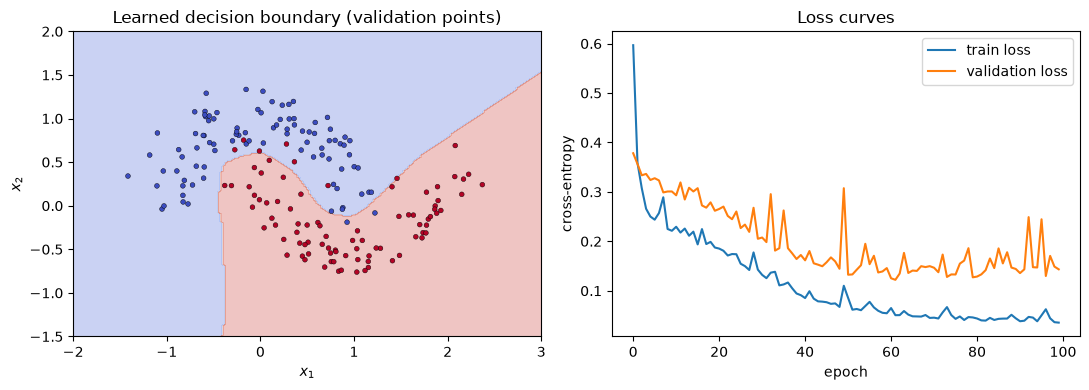

In [8]:
# Decision boundary: evaluate the network on a grid of points.
xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
moon_net.eval()
zz = moon_net.forward(grid).argmax(1).reshape(xx.shape)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].contourf(xx, yy, zz, alpha=0.3, cmap="coolwarm")
ax[0].scatter(Xm_va[:, 0], Xm_va[:, 1], c=ym_va, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.3)
ax[0].set_title("Learned decision boundary (validation points)"); ax[0].set_xlabel("$x_1$"); ax[0].set_ylabel("$x_2$")
ax[1].plot(h["loss"], label="train loss"); ax[1].plot(h["val_loss"], label="validation loss")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("cross-entropy"); ax[1].set_title("Loss curves"); ax[1].legend()
plt.tight_layout(); plt.show()

In [9]:
# The same code on digits: 64 -> 128 -> 10.
rng = np.random.default_rng(SEED)
digit_net = Sequential(Linear(64, 128, rng=rng), ReLU(), Linear(128, 10, rng=rng))
t0 = time.perf_counter()
h_dig = train(digit_net, X_train, y_train, X_val, y_val, SGD(digit_net, lr=0.1), epochs=30, verbose=True)
print(f"digits validation accuracy {h_dig['val_acc'][-1]:.3f}  ({time.perf_counter()-t0:.1f}s, {digit_net.n_params()} params)")

epoch   0  loss 2.0403  val_acc 0.694
epoch  10  loss 0.2729  val_acc 0.938


epoch  20  loss 0.1595  val_acc 0.948
epoch  29  loss 0.1195  val_acc 0.958
digits validation accuracy 0.958  (0.3s, 9610 params)


**What just happened?** About 40 lines of NumPy learned a curved boundary between the two moons and reached high accuracy on handwritten digits within seconds. There is no magic in `loss.backward()`: it is the reversed loop in `Sequential.backward`, calling the formulas we derived.

> 🎓 **Exam / interview tip:** the cost of one training step is roughly **3× a forward pass**: one forward, and a backward that does about twice the work (for each Linear layer it computes both $\bar W$ and $\bar X$).

## 5. Initialisation experiments

> 💬 **In plain English:** if the starting weights are too small, the signal fades to nothing as it passes through the layers; too big, and it blows up or saturates. Good initialisation keeps the signal at about the same size in every layer.

For a layer $y = Wx$ with $n_{in}$ inputs, independent zero-mean weights of variance $\sigma^2$ and inputs of variance $v$, each output has variance $n_{in}\sigma^2 v$. To keep the variance constant from layer to layer:

| Scheme | Weight std | Designed for | Reason |
|---|---|---|---|
| **Zero** | 0 | nothing | every unit computes the same thing (**symmetry** is never broken) |
| **Too small** | 0.01 | - | variance shrinks by $n_{in}\sigma^2 = 256\times 10^{-4}\approx 0.026$ per layer → **vanishing** signal |
| **Too large** | 1.0 | - | variance grows ×256 per layer → tanh **saturates** at ±1, gradients vanish |
| **Xavier / Glorot** (2010) | $\sqrt{2/(n_{in}+n_{out})}$ | tanh, sigmoid | balances forward and backward variance |
| **He / Kaiming** (2015) | $\sqrt{2/n_{in}}$ | ReLU | ReLU zeroes half the inputs, so it needs twice the variance |

We push 1,000 random inputs through a 10-layer, 256-wide network and look at the activations of every layer.

In [10]:
def activation_stats(init, act_cls, depth=10, width=256, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.normal(size=(n, width))
    acts = []
    for _ in range(depth):
        x = act_cls().forward(Linear(width, width, init=init, rng=rng).forward(x))
        acts.append(x)
    return acts


configs = [("zero", 0.0, Tanh), ("too small (0.01)", 0.01, Tanh), ("too large (1.0)", 1.0, Tanh),
           ("Xavier + tanh", "xavier", Tanh), ("Xavier + ReLU", "xavier", ReLU), ("He + ReLU", "he", ReLU)]
all_acts = {name: activation_stats(init, act) for name, init, act in configs}

std_table = pd.DataFrame({name: [a.std() for a in acts] for name, acts in all_acts.items()},
                         index=[f"layer {i+1}" for i in range(10)])
print(std_table.T.map(lambda v: f"{v:.2e}"))

                   layer 1   layer 2   layer 3   layer 4   layer 5   layer 6  \
zero              0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00   
too small (0.01)  1.57e-01  2.50e-02  4.00e-03  6.42e-04  1.02e-04  1.65e-05   
too large (1.0)   9.75e-01  9.74e-01  9.74e-01  9.74e-01  9.74e-01  9.74e-01   
Xavier + tanh     6.29e-01  4.85e-01  4.07e-01  3.58e-01  3.20e-01  2.95e-01   
Xavier + ReLU     5.88e-01  4.01e-01  3.05e-01  2.20e-01  1.52e-01  1.02e-01   
He + ReLU         8.31e-01  8.01e-01  8.62e-01  8.80e-01  8.60e-01  8.16e-01   

                   layer 7   layer 8   layer 9  layer 10  
zero              0.00e+00  0.00e+00  0.00e+00  0.00e+00  
too small (0.01)  2.60e-06  4.22e-07  6.88e-08  1.12e-08  
too large (1.0)   9.74e-01  9.74e-01  9.74e-01  9.74e-01  
Xavier + tanh     2.70e-01  2.56e-01  2.45e-01  2.35e-01  
Xavier + ReLU     7.60e-02  5.18e-02  3.72e-02  2.76e-02  
He + ReLU         8.60e-01  8.29e-01  8.42e-01  8.83e-01  


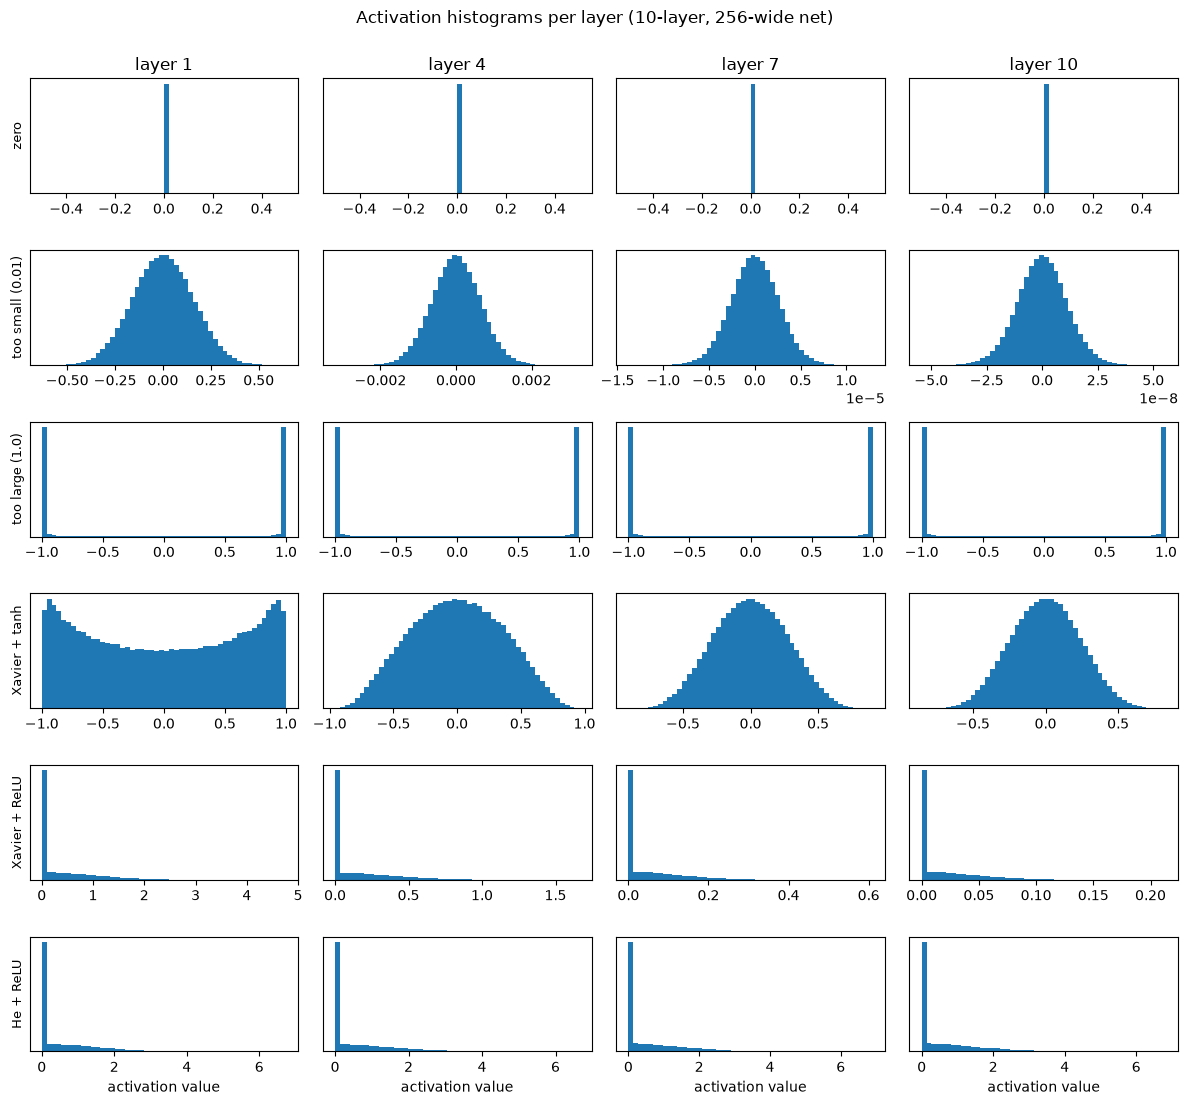

In [11]:
show_layers = [0, 3, 6, 9]
fig, axes = plt.subplots(len(configs), len(show_layers), figsize=(12, 11))
for r, (name, _, _) in enumerate(configs):
    for c, li in enumerate(show_layers):
        a = all_acts[name][li].ravel()
        axes[r, c].hist(a, bins=50, color="tab:blue")
        axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(f"layer {li+1}")
        if c == 0: axes[r, c].set_ylabel(name, fontsize=9)
        if r == len(configs) - 1: axes[r, c].set_xlabel("activation value")
fig.suptitle("Activation histograms per layer (10-layer, 256-wide net)", y=1.0)
plt.tight_layout(); plt.show()

**What just happened?** Read the table and the histograms row by row:

- **Zero:** every activation is exactly 0 in every layer (tanh(0) = 0), so nothing flows.
- **Too small:** the spread shrinks by about 40× per layer; by layer 10 it is around $10^{-16}$, effectively zero. Gradients vanish the same way on the way back.
- **Too large:** almost every tanh output is pinned at −1 or +1 (two spikes in the histogram). In those flat regions $1 - y^2 \approx 0$, so gradients vanish again.
- **Xavier + tanh:** a healthy, bell-shaped spread that only shrinks slowly. **He + ReLU:** the spread stays roughly constant across all 10 layers. **Xavier + ReLU** slowly fades (each layer roughly halves the variance), which is exactly the factor of 2 that He initialisation fixes.

### 5.1 Why zero (or any constant) initialisation fails: symmetry

> 💬 **In plain English:** if all hidden units start identical, they get identical gradients, so they stay identical forever: 128 units behave like 1.

In [12]:
rng = np.random.default_rng(SEED)
sym_net = Sequential(Linear(64, 16, init=0.0, rng=rng), Tanh(), Linear(16, 10, init=0.0, rng=rng))
for layer in sym_net.param_layers():
    layer.params["W"][:] = 0.05                          # constant (not random) start
train(sym_net, X_train, y_train, X_val, y_val, SGD(sym_net, lr=0.5), epochs=20)
W1 = sym_net.layers[0].params["W"]
print("max difference between the 16 hidden units' weight columns:", np.abs(W1 - W1[:, :1]).max())
print("distinct hidden units:", np.unique(W1.round(10), axis=1).shape[1])
print("validation accuracy:", round(accuracy(sym_net, X_val, y_val), 3))

max difference between the 16 hidden units' weight columns: 0.0
distinct hidden units: 1
validation accuracy: 0.34


**What just happened?** After 20 epochs of training the 16 hidden units are still exact copies of each other (difference 0, one distinct column), so the network is no better than one with a single hidden unit, and its accuracy is far below the random-init digit network above. **Random** initialisation breaks the symmetry; **scaled** random initialisation (Xavier/He) also keeps signals healthy.

> ⚠️ **Common mistake:** "biases can be zero, so weights can be zero too." Biases *can* start at zero because the random weights already break symmetry; weights cannot.

## 6. Optimisers from scratch

> 💬 **In plain English:** an optimiser decides how big a step to take and in which direction, using the gradient (and, for smarter ones, a memory of past gradients).

| Optimiser | Update rule (per parameter, gradient $g_t$) | Idea |
|---|---|---|
| **SGD** | $\theta \leftarrow \theta - \eta g_t$ | walk downhill |
| **Momentum** (heavy ball, PyTorch form) | $v \leftarrow \mu v + g_t;\ \ \theta \leftarrow \theta - \eta v$ | a rolling ball that keeps its speed, damping zig-zags |
| **Adam** (Kingma & Ba, 2015) | $m \leftarrow \beta_1 m + (1-\beta_1)g;\ \ s \leftarrow \beta_2 s + (1-\beta_2)g^2;$ $\hat m = m/(1-\beta_1^t),\ \hat s = s/(1-\beta_2^t);\ \ \theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat s}+\epsilon)$ | momentum + a per-parameter step size; $\hat{}$ = **bias correction** for the zero start |

Defaults: $\mu = 0.9$; Adam $\beta_1 = 0.9,\ \beta_2 = 0.999,\ \epsilon = 10^{-8}$. Each keeps $O(P)$ extra memory (momentum: 1 copy of the parameters, Adam: 2).

In [13]:
class Momentum(SGD):
    def __init__(self, model, lr=0.05, mu=0.9, weight_decay=0.0):
        super().__init__(model, lr, weight_decay)
        self.mu = mu
        self.v = {(id(l), k): np.zeros_like(p) for l in model.param_layers() for k, p in l.params.items()}

    def step(self):
        for layer in self.model.param_layers():
            for k, p in layer.params.items():
                g = layer.grads[k] + (self.wd * p if self.wd and k == "W" else 0.0)
                v = self.v[(id(layer), k)]
                v *= self.mu; v += g                     # velocity = decayed old velocity + new gradient
                p -= self.lr * v


class Adam(SGD):
    def __init__(self, model, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8, weight_decay=0.0):
        super().__init__(model, lr, weight_decay)
        self.b1, self.b2, self.eps, self.t = b1, b2, eps, 0
        keys = [(id(l), k, p) for l in model.param_layers() for k, p in l.params.items()]
        self.m = {(i, k): np.zeros_like(p) for i, k, p in keys}
        self.s = {(i, k): np.zeros_like(p) for i, k, p in keys}

    def step(self):
        self.t += 1
        for layer in self.model.param_layers():
            for k, p in layer.params.items():
                g = layer.grads[k] + (self.wd * p if self.wd and k == "W" else 0.0)
                m, s = self.m[(id(layer), k)], self.s[(id(layer), k)]
                m *= self.b1; m += (1 - self.b1) * g             # first moment (mean of g)
                s *= self.b2; s += (1 - self.b2) * g * g         # second moment (mean of g^2)
                m_hat = m / (1 - self.b1 ** self.t)              # bias correction
                s_hat = s / (1 - self.b2 ** self.t)
                p -= self.lr * m_hat / (np.sqrt(s_hat) + self.eps)


# Sanity check against torch.optim.Adam on one tensor for 5 steps (same gradients).
import torch
torch.set_num_threads(2)
p_np = np.array([[1.0, -2.0, 3.0]]); fake = Sequential(Linear(1, 3)); fake.layers[0].params = {"W": p_np}
opt_np = Adam(fake, lr=0.1)
p_t = torch.tensor(p_np.copy(), requires_grad=True); opt_t = torch.optim.Adam([p_t], lr=0.1)
for t in range(5):
    g = np.array([[0.5, -1.0, 2.0]]) * (t + 1)
    fake.layers[0].grads = {"W": g}; opt_np.step()
    p_t.grad = torch.tensor(g); opt_t.step()
print("ours :", p_np.ravel()); print("torch:", p_t.detach().numpy().ravel())
assert np.allclose(p_np, p_t.detach().numpy())

ours : [ 0.5149 -1.5149  2.5149]
torch: [ 0.5149 -1.5149  2.5149]


**What just happened?** Our Adam produces exactly the same parameters as `torch.optim.Adam` after 5 steps, so the update rule (including bias correction) is right.

### 6.1 Seeing the difference on an ill-conditioned valley

A loss $f(a,b) = \tfrac12(a^2 + 100\, b^2)$ is a long, narrow valley: the curvature in $b$ is 100× the curvature in $a$ (a **condition number** of 100). Gradient descent on a quadratic is only stable if $\eta < 2/\lambda_{max} = 2/100$, so plain SGD must use a tiny step and then crawls along the flat $a$ direction, where each step shrinks $a$ by only a factor $(1-\eta)$.

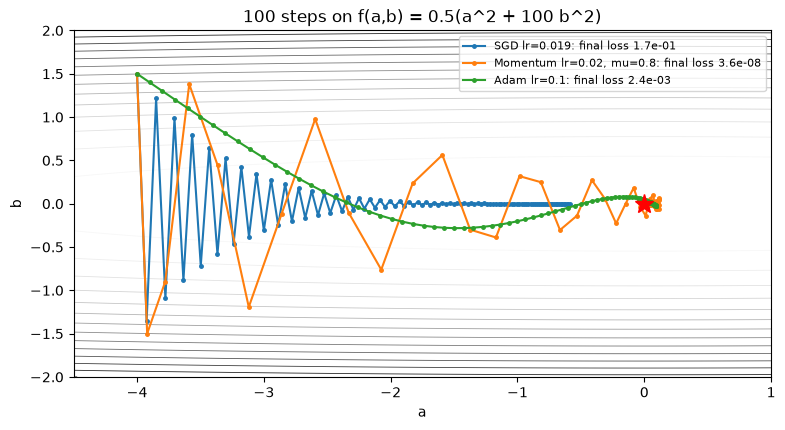

In [14]:
def run_on_valley(make_opt, steps=100, start=(-4.0, 1.5)):
    holder = Sequential(Linear(1, 2)); layer = holder.layers[0]
    layer.params = {"W": np.array([list(start)])}
    opt = make_opt(holder)
    path = [layer.params["W"].ravel().copy()]
    for _ in range(steps):
        a, b = layer.params["W"].ravel()
        layer.grads = {"W": np.array([[a, 100 * b]])}         # gradient of 0.5*(a^2 + 100 b^2)
        opt.step()
        path.append(layer.params["W"].ravel().copy())
    return np.array(path)


paths = {"SGD lr=0.019": run_on_valley(lambda m: SGD(m, lr=0.019)),           # just below the 0.02 limit
         "Momentum lr=0.02, mu=0.8": run_on_valley(lambda m: Momentum(m, lr=0.02, mu=0.8)),
         "Adam lr=0.1": run_on_valley(lambda m: Adam(m, lr=0.1))}
A, B = np.meshgrid(np.linspace(-4.5, 1, 200), np.linspace(-2, 2, 200))
plt.figure(figsize=(9, 4.5))
plt.contour(A, B, 0.5 * (A ** 2 + 100 * B ** 2), levels=20, cmap="Greys", linewidths=0.6)
for name, p in paths.items():
    plt.plot(p[:, 0], p[:, 1], "o-", ms=2.5, label=f"{name}: final loss {0.5*(p[-1,0]**2+100*p[-1,1]**2):.1e}")
plt.plot(0, 0, "r*", ms=14); plt.xlabel("a"); plt.ylabel("b"); plt.legend(fontsize=8)
plt.title("100 steps on f(a,b) = 0.5(a^2 + 100 b^2)"); plt.show()

**What just happened?** SGD, with a learning rate just under its stability limit, zig-zags across the narrow direction and is still far from the minimum along the flat direction after 100 steps (final loss around $10^{-1}$). Momentum accumulates speed along the valley floor and reaches a loss around $10^{-8}$. Adam divides each coordinate by its own gradient size, so both directions move at a similar pace (final loss around $10^{-3}$; with a constant learning rate it then hovers near the minimum). Momentum's coefficient matters: on this problem $\mu = 0.9$ overshoots and spirals, which is why it is tuned together with the learning rate.

### 6.2 Optimisers on digits

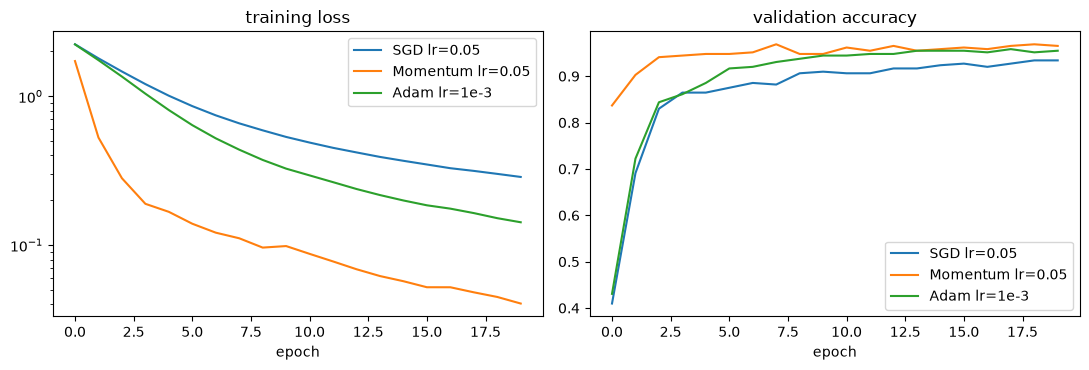

                  final train loss  val acc
SGD lr=0.05                 0.2870   0.9340
Momentum lr=0.05            0.0405   0.9653
Adam lr=1e-3                0.1424   0.9549


In [15]:
def fresh_digit_net(seed=SEED, hidden=128):
    rng = np.random.default_rng(seed)
    return Sequential(Linear(64, hidden, rng=rng), ReLU(), Linear(hidden, 10, rng=rng))

opt_results = {}
for name, make in [("SGD lr=0.05", lambda m: SGD(m, lr=0.05)),
                   ("Momentum lr=0.05", lambda m: Momentum(m, lr=0.05)),
                   ("Adam lr=1e-3", lambda m: Adam(m, lr=1e-3))]:
    net = fresh_digit_net()
    opt_results[name] = train(net, X_train, y_train, X_val, y_val, make(net), epochs=20)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, hh in opt_results.items():
    ax[0].plot(hh["loss"], label=name); ax[1].plot(hh["val_acc"], label=name)
ax[0].set_yscale("log"); ax[0].set_title("training loss"); ax[1].set_title("validation accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame({k: {"final train loss": v["loss"][-1], "val acc": v["val_acc"][-1]} for k, v in opt_results.items()}).T)

**What just happened?** With the same number of epochs and the same network, momentum reaches a much lower training loss than plain SGD at the same learning rate, and the best validation accuracy. Adam with its common default $10^{-3}$ sits in between here; Adam's advantage is that it is much less sensitive to the choice of learning rate, not that it always wins.

### 6.3 The learning-rate finder

> 💬 **In plain English:** start with a tiny learning rate and multiply it a little after every mini-batch; the loss first barely moves, then drops fast, then explodes. Pick a rate a bit before the explosion.

This is the "LR range test" (Smith, 2017; popularised by fast.ai). Rule of thumb: choose roughly **one tenth of the LR where the smoothed loss is lowest**, or the point of steepest descent.

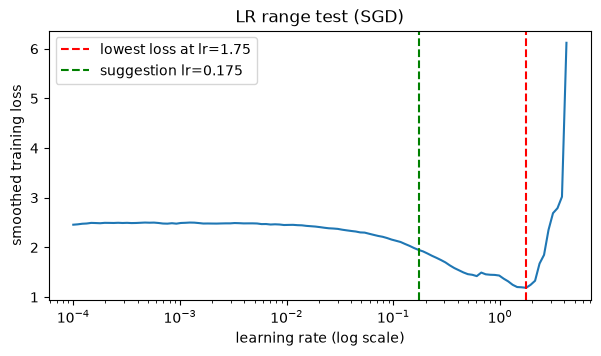

In [16]:
def lr_finder(make_net, make_opt, lr_min=1e-4, lr_max=10.0, steps=120, seed=0):
    net = make_net(); opt = make_opt(net); loss_fn = SoftmaxCrossEntropy()
    rng = np.random.default_rng(seed)
    factor = (lr_max / lr_min) ** (1 / (steps - 1))       # geometric growth per step
    lrs, losses, smooth, best = [], [], None, np.inf
    lr = lr_min
    for step in range(steps):
        b = rng.choice(len(X_train), 64, replace=False)
        opt.lr = lr
        loss = loss_fn.forward(net.forward(X_train[b]), y_train[b])
        net.backward(loss_fn.backward()); opt.step()
        smooth = loss if smooth is None else 0.9 * smooth + 0.1 * loss   # exponential smoothing
        lrs.append(lr); losses.append(smooth); best = min(best, smooth)
        if not np.isfinite(smooth) or smooth > 4 * best:  # stop once it explodes
            break
        lr *= factor
    return np.array(lrs), np.array(losses)

lrs, losses = lr_finder(fresh_digit_net, lambda m: SGD(m, lr=1e-4))
lr_at_min = lrs[np.argmin(losses)]
plt.figure(figsize=(7, 3.5)); plt.semilogx(lrs, losses)
plt.axvline(lr_at_min, color="r", ls="--", label=f"lowest loss at lr={lr_at_min:.2f}")
plt.axvline(lr_at_min / 10, color="g", ls="--", label=f"suggestion lr={lr_at_min/10:.3f}")
plt.xlabel("learning rate (log scale)"); plt.ylabel("smoothed training loss"); plt.title("LR range test (SGD)"); plt.legend()
plt.show()

### 6.4 Learning-rate schedules

> 💬 **In plain English:** take big steps early to make fast progress, then smaller steps to settle into a good minimum.

| Schedule | $\eta(t)$ | Typical use |
|---|---|---|
| Constant | $\eta_0$ | baselines |
| Step decay | $\eta_0\cdot\gamma^{\lfloor t/s\rfloor}$ | classic CNN training (ResNet: ×0.1 at fixed epochs) |
| Cosine | $\eta_0 \cdot \tfrac12(1+\cos(\pi t/T))$ | most modern training |
| Linear warm-up + cosine | linear ramp for $t<T_w$, then cosine | Transformers and LLMs (Adam is unstable with a large LR while its moment estimates are still noisy) |

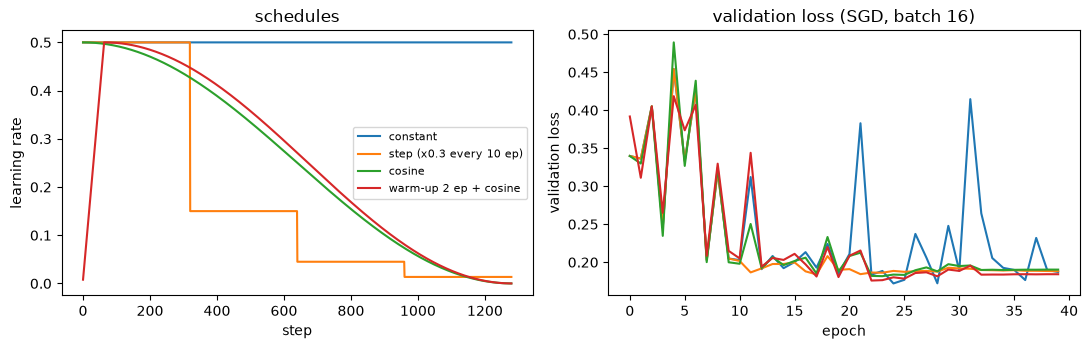

                         final train loss  val-loss std, last 10 epochs  \
constant                           0.0891                        0.0682   
step (x0.3 every 10 ep)            0.0820                        0.0012   
cosine                             0.0756                        0.0021   
warm-up 2 ep + cosine              0.0753                        0.0036   

                         final val acc  
constant                         0.942  
step (x0.3 every 10 ep)          0.946  
cosine                           0.946  
warm-up 2 ep + cosine            0.948  


In [17]:
# Digits is so easy that every schedule reaches ~0 training loss. Small mini-batches on a noisy
# problem (1,000 fresh two-moons points) make the effect of the learning rate visible.
X2, y2 = make_moons(n_samples=1000, noise=0.25, random_state=3)
X2_tr, y2_tr, X2_va, y2_va = X2[:500], y2[:500], X2[500:], y2[500:]
BS, EPOCHS, LR0 = 16, 40, 0.5
steps_per_epoch = int(np.ceil(len(X2_tr) / BS)); T = EPOCHS * steps_per_epoch; WARM = 2 * steps_per_epoch
schedules = {
    "constant": lambda t: LR0,
    "step (x0.3 every 10 ep)": lambda t: LR0 * 0.3 ** (t // (10 * steps_per_epoch)),
    "cosine": lambda t: LR0 * 0.5 * (1 + np.cos(np.pi * t / T)),
    "warm-up 2 ep + cosine": lambda t: LR0 * (t + 1) / WARM if t < WARM
        else LR0 * 0.5 * (1 + np.cos(np.pi * (t - WARM) / (T - WARM))),
}

def moon_mlp(seed=SEED):
    rng = np.random.default_rng(seed)
    return Sequential(Linear(2, 64, rng=rng), ReLU(), Linear(64, 64, rng=rng), ReLU(), Linear(64, 2, rng=rng))

sched_hist = {}
for name, sch in schedules.items():
    net = moon_mlp()
    sched_hist[name] = train(net, X2_tr, y2_tr, X2_va, y2_va, SGD(net, lr=LR0), epochs=EPOCHS, batch_size=BS, schedule=sch)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, sch in schedules.items():
    ax[0].plot([sch(t) for t in range(T)], label=name)
    ax[1].plot(sched_hist[name]["val_loss"], label=name)
ax[0].set_xlabel("step"); ax[0].set_ylabel("learning rate"); ax[0].set_title("schedules")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation loss"); ax[1].set_title("validation loss (SGD, batch 16)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(pd.DataFrame({k: {"final train loss": v["loss"][-1],
                        "val-loss std, last 10 epochs": np.std(v["val_loss"][-10:]),
                        "final val acc": v["val_acc"][-1]} for k, v in sched_hist.items()}).T)

**What just happened?** With a constant learning rate, the noise of 16-example mini-batches keeps kicking the weights around the minimum: the validation loss is still jumping up and down in the last epochs (see the standard-deviation column). Every decaying schedule takes small steps at the end, so the weights settle: lower final training loss and a validation loss that is far steadier, which also makes "the checkpoint at the end of training" a reliable one. Accuracy is similar for all four on this small problem; the differences grow with longer, harder training runs.

> 🎓 **Exam / interview tip:** "Why warm-up?" Early in training, Adam's second-moment estimate is based on very few gradients, so the per-parameter step $\hat m/\sqrt{\hat s}$ can be huge and erratic; warm-up keeps steps small until the statistics settle (this also motivated RAdam).

## 7. Regularisation: L2, dropout, early stopping

> 💬 **In plain English:** regularisation stops a network from memorising the training set: keep weights small (L2), make it work even when random parts are switched off (dropout), or simply stop training when validation results stop improving (early stopping).

To make overfitting visible we train a large network (2→128→128→2, about 17k parameters) on only **80** noisy two-moons points.

- **L2 regularisation** adds $\frac{\lambda}{2}\lVert W\rVert^2$ to the loss, i.e. adds $\lambda W$ to the gradient. With plain SGD this is the same as **weight decay** ($W \leftarrow (1-\eta\lambda)W - \eta g$). With Adam it is *not* the same, which is why **AdamW** (Loshchilov & Hutter, 2019) decays weights separately from the adaptive step.
- **Inverted dropout** with keep probability $q$: during training, multiply each activation by a mask $m_i \sim \text{Bernoulli}(q)$ and divide by $q$, so the *expected* activation is unchanged; at evaluation time do nothing. Backward: $\bar x = \bar y \odot m / q$.
- **Early stopping:** keep the weights from the epoch with the best validation loss; stop after `patience` epochs without improvement.

In [18]:
class Dropout(Layer):
    def __init__(self, p_drop=0.5, seed=0):
        super().__init__()
        self.q = 1.0 - p_drop                      # keep probability
        self.seed = seed
        self.rng = np.random.default_rng(seed)

    def reset_rng(self):                           # used only by the gradient check (same mask every call)
        self.rng = np.random.default_rng(self.seed)

    def forward(self, x):
        if not self.training:                      # eval mode: identity
            return x
        self.mask = (self.rng.random(x.shape) < self.q) / self.q   # inverted: scale at train time
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


d = Dropout(0.5)
x = np.ones((10000, 1))
print("train mode: fraction kept", (d.forward(x) > 0).mean().round(3), " mean output", d.forward(x).mean().round(3))
d.training = False
print("eval mode : mean output", d.forward(x).mean())
print("grad check:", grad_check_layer(Dropout(0.3), np.random.default_rng(3).normal(size=(4, 5))))

train mode: fraction kept 0.499  mean output 0.989
eval mode : mean output 1.0
grad check: {'x': 1.34593472592673e-11}


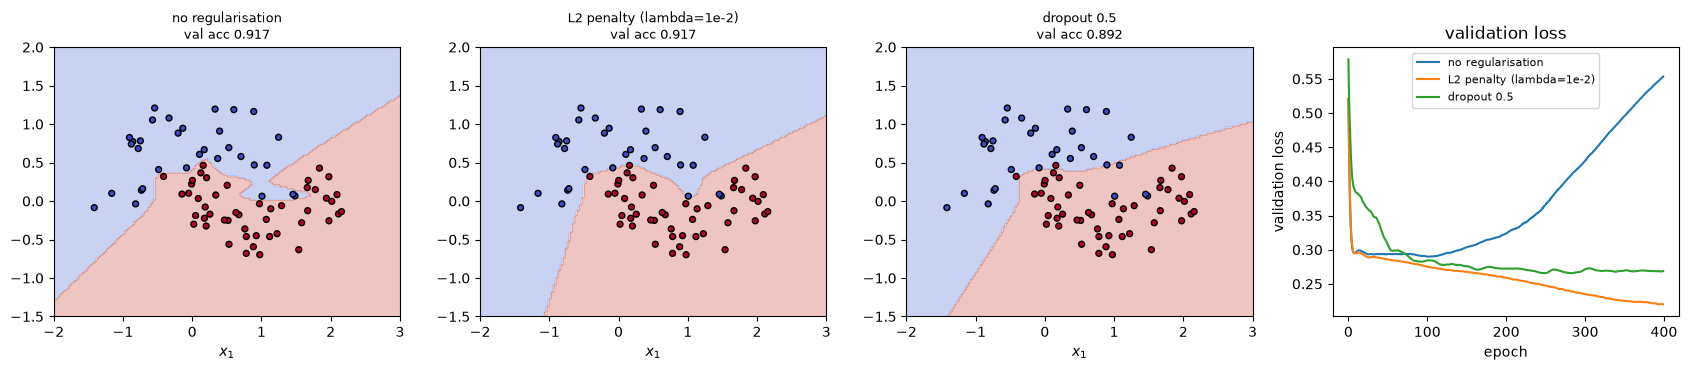

                          final train acc  final val acc  final val loss  \
no regularisation                   1.000         0.9175          0.5534   
L2 penalty (lambda=1e-2)            0.975         0.9175          0.2202   
dropout 0.5                         0.925         0.8925          0.2686   

                          best val loss  best epoch  
no regularisation                0.2899       101.0  
L2 penalty (lambda=1e-2)         0.2201       393.0  
dropout 0.5                      0.2657       282.0  


In [19]:
# Overfitting needs a big model and little data: 80 noisy two-moons points, a 2 -> 128 -> 128 -> 2 net (~17k params).
Xr, yr = make_moons(n_samples=480, noise=0.25, random_state=1)
Xr_tr, yr_tr, Xr_va, yr_va = Xr[:80], yr[:80], Xr[80:], yr[80:]

def big_net(dropout=0.0, seed=SEED):
    rng = np.random.default_rng(seed)
    layers = [Linear(2, 128, rng=rng), ReLU()]
    if dropout: layers.append(Dropout(dropout, seed=1))
    layers += [Linear(128, 128, rng=rng), ReLU()]
    if dropout: layers.append(Dropout(dropout, seed=2))
    layers.append(Linear(128, 2, rng=rng))
    return Sequential(*layers)

reg_hist, reg_nets = {}, {}
for name, make_net, wd in [("no regularisation", lambda: big_net(), 0.0),
                           ("L2 penalty (lambda=1e-2)", lambda: big_net(), 1e-2),
                           ("dropout 0.5", lambda: big_net(0.5), 0.0)]:
    net = make_net()
    reg_hist[name] = train(net, Xr_tr, yr_tr, Xr_va, yr_va, Adam(net, lr=1e-3, weight_decay=wd), epochs=400, batch_size=80)
    reg_nets[name] = net

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
xx2, yy2 = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.5, 2, 150)); grid2 = np.c_[xx2.ravel(), yy2.ravel()]
for a, (name, net) in zip(ax[:3], reg_nets.items()):
    net.eval(); zz2 = net.forward(grid2).argmax(1).reshape(xx2.shape); net.train()
    a.contourf(xx2, yy2, zz2, alpha=0.3, cmap="coolwarm")
    a.scatter(Xr_tr[:, 0], Xr_tr[:, 1], c=yr_tr, cmap="coolwarm", s=18, edgecolor="k")
    a.set_title(f"{name}\nval acc {reg_hist[name]['val_acc'][-1]:.3f}", fontsize=9); a.set_xlabel("$x_1$")
for name, hh in reg_hist.items():
    ax[3].plot(hh["val_loss"], label=name)
ax[3].set_xlabel("epoch"); ax[3].set_ylabel("validation loss"); ax[3].set_title("validation loss"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

summary = {}
for name, hh in reg_hist.items():
    summary[name] = {"final train acc": hh["train_acc"][-1], "final val acc": hh["val_acc"][-1],
                     "final val loss": hh["val_loss"][-1], "best val loss": min(hh["val_loss"]),
                     "best epoch": int(np.argmin(hh["val_loss"]))}
print(pd.DataFrame(summary).T)

In [20]:
def train_early_stopping(make_net, patience=60, max_epochs=400):
    net = make_net(); opt = Adam(net, lr=1e-3)
    best_loss, best_epoch, best_params, waited = np.inf, -1, None, 0
    loss_fn = SoftmaxCrossEntropy()
    for epoch in range(max_epochs):
        net.train()
        loss_fn.forward(net.forward(Xr_tr), yr_tr); net.backward(loss_fn.backward()); opt.step()   # full batch
        net.eval(); vl = loss_fn.forward(net.forward(Xr_va), yr_va)
        if vl < best_loss - 1e-4:                                     # improved: remember these weights
            best_loss, best_epoch, waited = vl, epoch, 0
            best_params = [{k: p.copy() for k, p in l.params.items()} for l in net.param_layers()]
        else:
            waited += 1
            if waited >= patience:                                    # no improvement for `patience` epochs
                break
    for l, saved in zip(net.param_layers(), best_params):            # restore the best checkpoint
        for k in l.params: l.params[k][...] = saved[k]
    return net, best_epoch, epoch

es_net, best_epoch, stopped = train_early_stopping(big_net)
lf = SoftmaxCrossEntropy(); es_net.eval()
print(f"stopped at epoch {stopped}, restored epoch {best_epoch}:  val loss {lf.forward(es_net.forward(Xr_va), yr_va):.3f}, "
      f"val acc {accuracy(es_net, Xr_va, yr_va):.3f}")
print(f"un-regularised after 400 epochs: val loss {reg_hist['no regularisation']['val_loss'][-1]:.3f}, "
      f"val acc {reg_hist['no regularisation']['val_acc'][-1]:.3f}")

stopped at epoch 161, restored epoch 101:  val loss 0.290, val acc 0.880
un-regularised after 400 epochs: val loss 0.553, val acc 0.917


**What just happened?** With only 80 noisy points, the un-regularised network reaches 100% training accuracy by carving pockets around individual training points (it memorises). Its validation loss reaches a minimum after about 100 epochs and then **climbs** steadily, roughly doubling by epoch 400: the classic overfitting curve. The L2 penalty keeps the boundary smooth and its validation loss keeps falling, ending far below the un-regularised one; dropout lands in between. Early stopping restores the minimum-validation-loss epoch and stops long before 400 epochs.

Look closely at accuracy, though: on this toy problem the accuracies differ by only a few points, and the early-stopped model is a few points *less* accurate than the over-trained one. Validation **loss** is the more sensitive signal: an overfit model becomes **over-confident**, so the few points it gets wrong cost a lot of loss. Calibrated probabilities matter whenever a prediction feeds a decision (medicine, credit, ranking), which is why we monitor the loss and not only accuracy.

> ⚠️ **Common mistake:** forgetting `model.eval()` at test time. Dropout then keeps randomly zeroing units, so predictions are noisy and accuracy drops. The mirror mistake is forgetting `model.train()` before the next epoch, which silently turns dropout off.

## 8. Batch normalisation from scratch

> 💬 **In plain English:** BatchNorm re-centres and re-scales each feature using the current mini-batch, so every layer receives inputs of a predictable size; then two learnable numbers let the network undo that if it wants.

**Definition** (Ioffe & Szegedy, 2015). For a mini-batch $x\in\mathbb{R}^{N\times D}$, per feature $j$:

$$\mu_j = \tfrac1N\sum_n x_{nj},\quad \sigma_j^2 = \tfrac1N\sum_n (x_{nj}-\mu_j)^2,\quad \hat x_{nj} = \frac{x_{nj}-\mu_j}{\sqrt{\sigma_j^2+\epsilon}},\quad y_{nj} = \gamma_j\hat x_{nj} + \beta_j.$$

At **training** time it uses the batch statistics and updates **running** averages $\mu_{run} \leftarrow (1-m)\mu_{run} + m\mu$ (PyTorch uses momentum $m=0.1$ and the *unbiased* variance for the running value). At **evaluation** time it uses the running averages, so the output for one example does not depend on the rest of the batch.

**Backward.** Every $\hat x_{nj}$ depends on all $x_{\cdot j}$ through $\mu_j$ and $\sigma_j$, which gives three terms. Writing $g = \bar y \odot \gamma$ (the gradient w.r.t. $\hat x$):

$$\bar\gamma = \sum_n \bar y \odot \hat x,\qquad \bar\beta = \sum_n \bar y,\qquad \bar x = \frac{1}{N\sqrt{\sigma^2+\epsilon}}\Big(N g - \sum_n g - \hat x \odot \sum_n (g\odot\hat x)\Big).$$

Intuition: the gradient that reaches $x$ has its mean removed (because shifting all of $x$ does nothing after centring) and its component along $\hat x$ removed (because scaling all of $x$ does nothing after normalising).

In [21]:
class BatchNorm1d(Layer):
    def __init__(self, dim, momentum=0.1, eps=1e-5):
        super().__init__()
        self.params["gamma"] = np.ones(dim)            # scale, starts at 1
        self.params["beta"] = np.zeros(dim)            # shift, starts at 0
        self.running_mean, self.running_var = np.zeros(dim), np.ones(dim)
        self.m, self.eps = momentum, eps

    def forward(self, x):
        if self.training:
            mu, var = x.mean(axis=0), x.var(axis=0)    # batch statistics (biased variance)
            n = x.shape[0]
            self.running_mean = (1 - self.m) * self.running_mean + self.m * mu
            self.running_var = (1 - self.m) * self.running_var + self.m * var * n / (n - 1)   # unbiased, like PyTorch
        else:
            mu, var = self.running_mean, self.running_var
        self.inv_std = 1.0 / np.sqrt(var + self.eps)
        self.xhat = (x - mu) * self.inv_std
        return self.params["gamma"] * self.xhat + self.params["beta"]

    def backward(self, dout):
        n = dout.shape[0]
        self.grads["gamma"] = (dout * self.xhat).sum(axis=0)
        self.grads["beta"] = dout.sum(axis=0)
        g = dout * self.params["gamma"]                # gradient w.r.t. xhat
        return self.inv_std / n * (n * g - g.sum(axis=0) - self.xhat * (g * self.xhat).sum(axis=0))


rng = np.random.default_rng(7)
bn = BatchNorm1d(4); bn.params["gamma"] = rng.normal(size=4); bn.params["beta"] = rng.normal(size=4)
print("BatchNorm grad check:", grad_check_layer(bn, rng.normal(2.0, 3.0, size=(6, 4))))

# Compare forward + running statistics with torch.nn.BatchNorm1d over 3 training batches, then eval.
ours, theirs = BatchNorm1d(4), torch.nn.BatchNorm1d(4).double()
for i in range(3):
    xb = rng.normal(1.0, 2.0, size=(8, 4))
    a, b = ours.forward(xb), theirs(torch.tensor(xb)).detach().numpy()
    assert np.allclose(a, b)
ours.training = False; theirs.eval(); xt = rng.normal(size=(5, 4))
print("eval-mode max |ours - torch|:", np.abs(ours.forward(xt) - theirs(torch.tensor(xt)).detach().numpy()).max())
print("running mean ours :", ours.running_mean.round(4)); print("running mean torch:", theirs.running_mean.numpy().round(4))

BatchNorm grad check: {'x': 3.4818573756731885e-08, 'gamma': 1.1603646145727118e-11, 'beta': 1.129954259075753e-11}
eval-mode max |ours - torch|: 2.220446049250313e-16
running mean ours : [0.105  0.2088 0.3346 0.2346]
running mean torch: [0.105  0.2088 0.3346 0.2346]


**What just happened?** The gradient check passes for the input, $\gamma$ and $\beta$, and our layer matches `torch.nn.BatchNorm1d` both in training mode and in evaluation mode with running statistics (differences around $10^{-15}$, i.e. floating-point round-off).

Now the payoff: a deep (8 hidden layers) **sigmoid** network is hard to train with plain SGD, because sigmoid's derivative is at most 0.25 and gradients shrink at every layer. Adding BatchNorm before each activation keeps the pre-activations centred where sigmoid is steep.

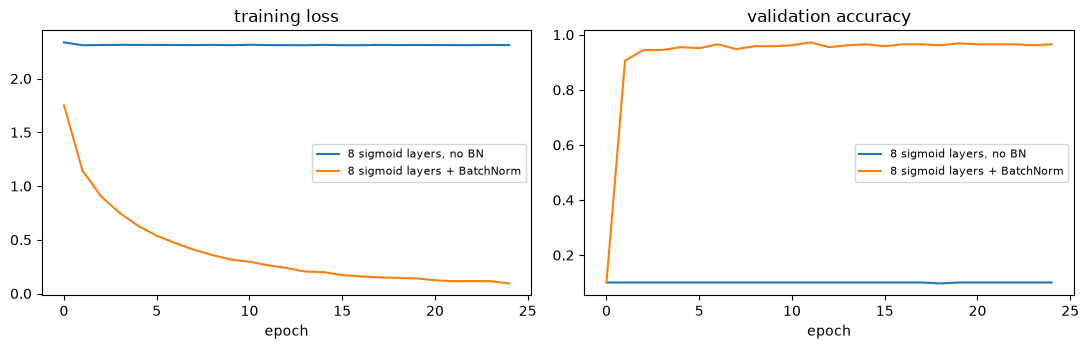

8 sigmoid layers, no BN          final val acc 0.101
8 sigmoid layers + BatchNorm     final val acc 0.965


In [22]:
def deep_sigmoid(bn, depth=8, width=64, seed=SEED):
    rng = np.random.default_rng(seed)
    layers, n_in = [], 64
    for _ in range(depth):
        layers.append(Linear(n_in, width, init="xavier", rng=rng))
        if bn: layers.append(BatchNorm1d(width))
        layers.append(Sigmoid()); n_in = width
    layers.append(Linear(n_in, 10, init="xavier", rng=rng))
    return Sequential(*layers)

bn_hist = {}
for name, use_bn in [("8 sigmoid layers, no BN", False), ("8 sigmoid layers + BatchNorm", True)]:
    net = deep_sigmoid(use_bn)
    bn_hist[name] = train(net, X_train, y_train, X_val, y_val, SGD(net, lr=0.1), epochs=25)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, hh in bn_hist.items():
    ax[0].plot(hh["loss"], label=name); ax[1].plot(hh["val_acc"], label=name)
ax[0].set_title("training loss"); ax[1].set_title("validation accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
for name, hh in bn_hist.items():
    print(f"{name:32s} final val acc {hh['val_acc'][-1]:.3f}")

**What just happened?** Without BatchNorm the deep sigmoid network never leaves chance level (about 10% validation accuracy): its loss sits on the plateau at $\ln 10 \approx 2.30$, which means "predict uniform probabilities". With BatchNorm the same network trains quickly to high accuracy. Same data, same optimiser, same learning rate.

> ⚠️ **Common mistake:** using BatchNorm with tiny batches (2-4) or in sequence models with variable lengths; batch statistics become very noisy. Transformers use **LayerNorm** (normalise across features of each example, no batch dependence) or **RMSNorm** instead. LayerNorm's backward is Practice problem 7.

**Complexity:** $O(ND)$ time and memory for forward and backward; parameters $2D$, plus $2D$ running buffers that are not trained.

## 9. Convolutions via im2col, MaxPool, and a tiny CNN

> 💬 **In plain English:** a convolution slides a small stencil over the image and, at every position, computes a weighted sum. im2col copies every image patch into a row of a big matrix, so all those weighted sums become **one** matrix multiplication.

**Definition** (as implemented in deep-learning libraries, which actually compute *cross-correlation*). Input $x\in\mathbb{R}^{N\times C\times H\times W}$, filters $w\in\mathbb{R}^{F\times C\times k\times k}$, bias $b\in\mathbb{R}^F$, stride $s$, zero padding $p$:

$$y_{n,f,i,j} = b_f + \sum_{c=0}^{C-1}\sum_{u=0}^{k-1}\sum_{v=0}^{k-1} w_{f,c,u,v}\; x^{pad}_{n,c,\,si+u,\,sj+v},\qquad H_{out} = \Big\lfloor\frac{H + 2p - k}{s}\Big\rfloor + 1.$$

**im2col.** Put every $C\times k\times k$ patch into one row of a matrix $X_{col}\in\mathbb{R}^{(N H_{out} W_{out})\times(Ck^2)}$ and reshape the filters to $W_{row}\in\mathbb{R}^{F\times Ck^2}$. Then $Y = X_{col}W_{row}^\top$, one big matrix product (GEMM), which is what BLAS libraries are fastest at. The price is memory: each input pixel is copied up to $k^2$ times.

**Hand example** (1 channel, 3×3 input, 2×2 filter, stride 1, no padding → 2×2 output, 4 patches):

```
input          filter       im2col rows (one per output position)      output
1 2 3          1 0          patch(0,0): [1 2 4 5]  . [1 0 0 -1] = 1-5 = -4     -4 -4
4 5 6          0 -1         patch(0,1): [2 3 5 6]  . [1 0 0 -1] = 2-6 = -4     -4 -4
7 8 9                       patch(1,0): [4 5 7 8]  . [1 0 0 -1] = 4-8 = -4
                            patch(1,1): [5 6 8 9]  . [1 0 0 -1] = 5-9 = -4
```

**Backward.** With $\bar Y$ reshaped to $(N H_{out} W_{out})\times F$: $\bar W_{row} = \bar Y^\top X_{col}$, $\bar b = \sum \bar Y$, and $\bar X_{col} = \bar Y W_{row}$, which **col2im** scatters back by *adding* every patch gradient to the pixels it came from (a pixel used by several patches receives the sum).

In [23]:
from numpy.lib.stride_tricks import sliding_window_view

def im2col(x, k, stride, pad):
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))          # zero padding
    win = sliding_window_view(xp, (k, k), axis=(2, 3))[:, :, ::stride, ::stride]   # (N, C, Ho, Wo, k, k) view
    n, c, ho, wo = win.shape[:4]
    cols = win.transpose(0, 2, 3, 1, 4, 5).reshape(n * ho * wo, c * k * k)        # one row per output pixel
    return cols, xp.shape, ho, wo


class Conv2D(Layer):
    def __init__(self, c_in, c_out, k=3, stride=1, pad=1, rng=None):
        super().__init__()
        rng = rng if rng is not None else np.random.default_rng(SEED)
        self.k, self.stride, self.pad = k, stride, pad
        self.params["W"] = rng.normal(0, np.sqrt(2.0 / (c_in * k * k)), size=(c_out, c_in, k, k))   # He init
        self.params["b"] = np.zeros(c_out)

    def forward(self, x):
        self.x_shape = x.shape
        self.cols, self.xp_shape, self.ho, self.wo = im2col(x, self.k, self.stride, self.pad)
        W = self.params["W"]
        out = self.cols @ W.reshape(W.shape[0], -1).T + self.params["b"]      # the single GEMM
        n = x.shape[0]
        return out.reshape(n, self.ho, self.wo, -1).transpose(0, 3, 1, 2)       # back to (N, F, Ho, Wo)

    def backward(self, dout):
        W = self.params["W"]; F = W.shape[0]; k, s = self.k, self.stride
        d = dout.transpose(0, 2, 3, 1).reshape(-1, F)                           # (N*Ho*Wo, F)
        self.grads["W"] = (d.T @ self.cols).reshape(W.shape)
        self.grads["b"] = d.sum(axis=0)
        dcols = (d @ W.reshape(F, -1)).reshape(self.x_shape[0], self.ho, self.wo, self.x_shape[1], k, k)
        dxp = np.zeros(self.xp_shape)
        for u in range(k):                                                      # col2im: scatter-add
            for v in range(k):
                dxp[:, :, u:u + s * self.ho:s, v:v + s * self.wo:s] += dcols[:, :, :, :, u, v].transpose(0, 3, 1, 2)
        p = self.pad
        return dxp[:, :, p:dxp.shape[2] - p, p:dxp.shape[3] - p] if p else dxp


# Hand example from the markdown
conv = Conv2D(1, 1, k=2, pad=0)
conv.params["W"] = np.array([[[[1.0, 0.0], [0.0, -1.0]]]])
x_hand = np.arange(1, 10, dtype=float).reshape(1, 1, 3, 3)
print("im2col rows:\n", im2col(x_hand, 2, 1, 0)[0])
print("output:\n", conv.forward(x_hand)[0, 0])

im2col rows:
 [[1. 2. 4. 5.]
 [2. 3. 5. 6.]
 [4. 5. 7. 8.]
 [5. 6. 8. 9.]]
output:
 [[-4. -4.]
 [-4. -4.]]


In [24]:
def conv_naive(x, W, b, stride, pad):
    # Seven nested loops written straight from the definition, used only to test im2col.
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
    n_, c_, h_, w_ = x.shape; f_, _, k, _ = W.shape
    ho, wo = (h_ + 2 * pad - k) // stride + 1, (w_ + 2 * pad - k) // stride + 1
    y = np.zeros((n_, f_, ho, wo))
    for n in range(n_):
        for f in range(f_):
            for i in range(ho):
                for j in range(wo):
                    y[n, f, i, j] = b[f] + np.sum(W[f] * xp[n, :, i * stride:i * stride + k, j * stride:j * stride + k])
    return y

rng = np.random.default_rng(5)
for (n, c, h, w, f, k, s, p) in [(2, 3, 7, 7, 4, 3, 1, 1), (2, 2, 8, 6, 3, 3, 2, 1), (1, 1, 5, 5, 2, 2, 1, 0), (2, 3, 9, 9, 2, 5, 2, 2)]:
    conv = Conv2D(c, f, k=k, stride=s, pad=p, rng=rng); conv.params["b"] = rng.normal(size=f)
    x = rng.normal(size=(n, c, h, w))
    ours = conv.forward(x)
    ref = conv_naive(x, conv.params["W"], conv.params["b"], s, p)
    tconv = torch.nn.Conv2d(c, f, k, stride=s, padding=p).double()
    with torch.no_grad():
        tconv.weight.copy_(torch.tensor(conv.params["W"])); tconv.bias.copy_(torch.tensor(conv.params["b"]))
        tout = tconv(torch.tensor(x)).numpy()
    print(f"x{(n, c, h, w)} k={k} s={s} p={p} -> out {ours.shape}:  |ours-naive| {np.abs(ours-ref).max():.1e}  |ours-torch| {np.abs(ours-tout).max():.1e}")
    assert np.allclose(ours, ref) and np.allclose(ours, tout)

print("Conv2D grad check (stride 2, pad 1):", grad_check_layer(Conv2D(2, 3, k=3, stride=2, pad=1, rng=rng), rng.normal(size=(2, 2, 5, 5))))

x(2, 3, 7, 7) k=3 s=1 p=1 -> out (2, 4, 7, 7):  |ours-naive| 1.3e-15  |ours-torch| 4.4e-16
x(2, 2, 8, 6) k=3 s=2 p=1 -> out (2, 3, 4, 3):  |ours-naive| 6.7e-16  |ours-torch| 8.9e-16
x(1, 1, 5, 5) k=2 s=1 p=0 -> out (1, 2, 4, 4):  |ours-naive| 4.4e-16  |ours-torch| 8.9e-16
x(2, 3, 9, 9) k=5 s=2 p=2 -> out (2, 2, 5, 5):  |ours-naive| 1.1e-15  |ours-torch| 8.9e-16
Conv2D grad check (stride 2, pad 1): {'x': 6.593787248800064e-09, 'W': 1.5593576326740435e-10, 'b': 1.3142295099082861e-11}


**What just happened?** On four different shapes (including stride 2 and a 5×5 kernel), the im2col convolution equals the 7-loop definition **and** `torch.nn.Conv2d` up to about $10^{-15}$, and the gradient check passes for the input, the filters and the bias. So both the forward GEMM and the col2im scatter-add are right.

### 9.1 Max-pooling and flatten

> 💬 **In plain English:** max-pooling keeps only the strongest response in each 2×2 square; in backward, the whole gradient goes to the one pixel that won.

For non-overlapping 2×2 windows we can reshape $(N,C,H,W)\to(N,C,H/2,2,W/2,2)$ and take the max over the two size-2 axes. Backward routes $\bar y$ to the arg-max position of each window and zero elsewhere (the "switch" is cached).

In [25]:
class MaxPool2x2(Layer):
    def forward(self, x):
        n, c, h, w = x.shape
        win = x.reshape(n, c, h // 2, 2, w // 2, 2).transpose(0, 1, 2, 4, 3, 5).reshape(n, c, h // 2, w // 2, 4)
        self.arg = win.argmax(axis=-1)                       # which of the 4 pixels won
        self.x_shape = x.shape
        return win.max(axis=-1)

    def backward(self, dout):
        n, c, h, w = self.x_shape
        dwin = np.zeros((n, c, h // 2, w // 2, 4))
        np.put_along_axis(dwin, self.arg[..., None], dout[..., None], axis=-1)   # gradient only to the winner
        return dwin.reshape(n, c, h // 2, w // 2, 2, 2).transpose(0, 1, 2, 4, 3, 5).reshape(n, c, h, w)


class Flatten(Layer):
    def forward(self, x):
        self.shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, dout):
        return dout.reshape(self.shape)


xp_ = np.array([[[[1, 3, 2, 0], [4, 2, 1, 5], [0, 1, 7, 6], [2, 3, 8, 1]]]], dtype=float)
mp = MaxPool2x2(); print("max-pool of 4x4:\n", mp.forward(xp_)[0, 0])
print("backward of ones:\n", mp.backward(np.ones((1, 1, 2, 2)))[0, 0])
rng = np.random.default_rng(11)
assert np.allclose(MaxPool2x2().forward(xp_), torch.nn.functional.max_pool2d(torch.tensor(xp_), 2).numpy())
print("MaxPool grad check:", grad_check_layer(MaxPool2x2(), rng.normal(size=(2, 3, 4, 6))))
print("Flatten grad check:", grad_check_layer(Flatten(), rng.normal(size=(2, 3, 2, 2))))

max-pool of 4x4:
 [[4. 5.]
 [3. 8.]]
backward of ones:
 [[0. 0. 0. 0.]
 [1. 0. 0. 1.]
 [0. 0. 0. 0.]
 [0. 1. 1. 0.]]
MaxPool grad check: {'x': 7.036556308828593e-10}
Flatten grad check: {'x': 7.036556308828593e-10}


### 9.2 A tiny CNN on 8×8 digits

Architecture: `Conv(1→8, 3×3, pad 1) → ReLU → MaxPool 2×2 → Conv(8→16, 3×3, pad 1) → ReLU → MaxPool 2×2 → Flatten (16·2·2 = 64) → Linear(64→10)`.

| Layer | Output shape (per image) | Parameters |
|---|---|---|
| Conv 1→8, 3×3 | 8×8×8 | 8·1·9 + 8 = 80 |
| MaxPool | 8×4×4 | 0 |
| Conv 8→16, 3×3 | 16×4×4 | 16·8·9 + 16 = 1,168 |
| MaxPool | 16×2×2 | 0 |
| Linear 64→10 | 10 | 650 |
| **Total** | | **1,898** |

The MLP in Section 4 had 9,610 parameters; the CNN has 5× fewer because each filter is **shared** across all positions (weight sharing) and only looks at a 3×3 neighbourhood (local connectivity).

In [26]:
Xi_train, Xi_val, Xi_test = (a.reshape(-1, 1, 8, 8) for a in (X_train, X_val, X_test))
rng = np.random.default_rng(SEED)
cnn = Sequential(Conv2D(1, 8, rng=rng), ReLU(), MaxPool2x2(),
                 Conv2D(8, 16, rng=rng), ReLU(), MaxPool2x2(),
                 Flatten(), Linear(64, 10, rng=rng))
print("CNN parameters:", cnn.n_params())
t0 = time.perf_counter()
h_cnn = train(cnn, Xi_train, y_train, Xi_val, y_val, Adam(cnn, lr=3e-3), epochs=20, batch_size=32, verbose=True)
print(f"trained in {time.perf_counter()-t0:.1f}s")
mlp = fresh_digit_net(); h_mlp = train(mlp, X_train, y_train, X_val, y_val, Adam(mlp, lr=3e-3), epochs=20, batch_size=32)
print(f"TEST accuracy  CNN ({cnn.n_params()} params): {accuracy(cnn, Xi_test, y_test):.3f}   "
      f"MLP ({mlp.n_params()} params): {accuracy(mlp, X_test, y_test):.3f}")

CNN parameters: 1898


epoch   0  loss 2.3084  val_acc 0.486

epoch  10  loss 0.1066  val_acc 0.962


epoch  19  loss 0.0361  val_acc 0.976
trained in 4.1s


TEST accuracy  CNN (1898 params): 0.967   MLP (9610 params): 0.967


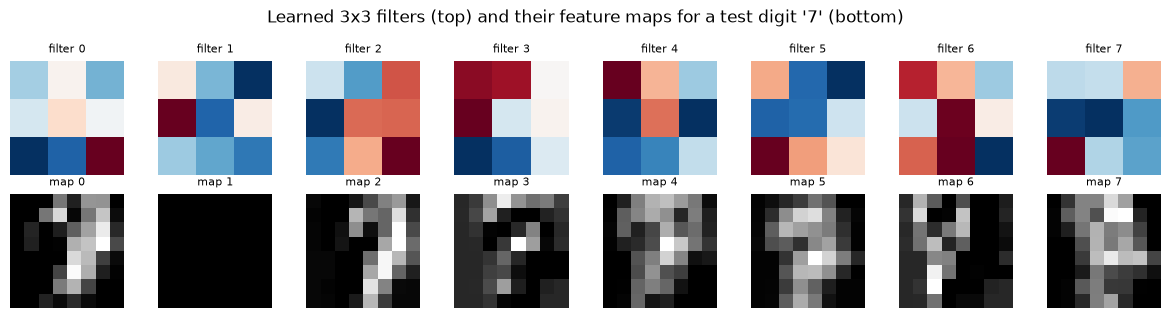

In [27]:
W1 = cnn.layers[0].params["W"]                                     # (8, 1, 3, 3) first-layer filters
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
sample = Xi_test[:1]
cnn.eval(); fmap = cnn.layers[1].forward(cnn.layers[0].forward(sample))   # ReLU(conv1(x)) for one test image
for f in range(8):
    ax[0, f].imshow(W1[f, 0], cmap="RdBu"); ax[0, f].set_title(f"filter {f}", fontsize=8)
    ax[1, f].imshow(fmap[0, f], cmap="gray"); ax[1, f].set_title(f"map {f}", fontsize=8)
for a in ax.ravel(): a.axis("off")
fig.suptitle(f"Learned 3x3 filters (top) and their feature maps for a test digit '{y_test[0]}' (bottom)")
plt.tight_layout(); plt.show()

**What just happened?** Our from-scratch CNN, with every forward and backward pass written by hand, trains in seconds on a CPU and matches the MLP's test accuracy with 5× fewer parameters. (On 8×8 images there is little spatial structure to exploit; on real-sized images the gap in favour of CNNs becomes large.) The first-layer filters look like small edge and stroke detectors, and the feature maps light up on different strokes of the digit.

**Complexity of a conv layer:** $O(N\cdot H_{out}W_{out}\cdot F\cdot Ck^2)$ multiply-adds; im2col memory $O(N H_{out}W_{out}Ck^2)$, i.e. about $k^2$ times the input size. Max-pool: $O(NCHW)$.

> 🎓 **Exam / interview tip:** output size $\lfloor (H+2p-k)/s\rfloor+1$; "same" padding for odd $k$ and stride 1 is $p=(k-1)/2$; parameters of a conv layer $= F\cdot C\cdot k^2 + F$, independent of the image size.

## 10. Training-diagnostics checklist

> 💬 **In plain English:** before blaming the data or the architecture, run a few cheap tests that catch most bugs: can the model memorise a handful of examples? does the loss curve look sane? are neurons dead? are gradients vanishing or exploding?

### 10.1 Overfit one batch

If a model cannot drive the loss to almost zero on **one** small batch, there is a bug (wrong labels, wrong loss, a broken backward pass, a learning rate that is far off). It is the single most useful sanity test.

In [28]:
xb, yb = X_train[:32], y_train[:32]
net = fresh_digit_net(); opt = Adam(net, lr=1e-2); loss_fn = SoftmaxCrossEntropy()
for step in range(201):
    loss = loss_fn.forward(net.forward(xb), yb); net.backward(loss_fn.backward()); opt.step()
    if step % 50 == 0:
        print(f"step {step:3d}  loss {loss:.5f}")
print("accuracy on that batch:", accuracy(net, xb, yb))
print("expected loss at step 0 for 10 balanced classes is about ln(10) =", round(np.log(10), 3))

step   0  loss 2.44951
step  50  loss 0.00093
step 100  loss 0.00050
step 150  loss 0.00037
step 200  loss 0.00028
accuracy on that batch: 1.0
expected loss at step 0 for 10 balanced classes is about ln(10) = 2.303


**What just happened?** The loss starts near $\ln 10 \approx 2.30$ (a freshly initialised classifier should be close to uniform: if it starts much higher, the initial logits are too large) and falls to almost zero, with 100% accuracy on the batch. The model and the backward pass can learn.

### 10.2 Reading loss curves

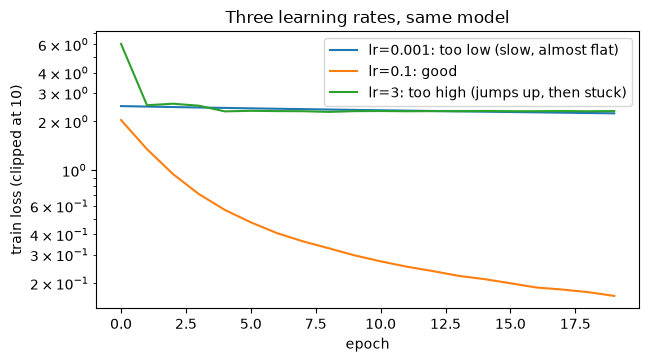

{0.001: 2.245, 0.1: 0.1668, 3.0: 2.3186}


In [29]:
curves = {}
for lr in [1e-3, 0.1, 3.0]:
    net = fresh_digit_net()
    with np.errstate(over="ignore", invalid="ignore"):          # the lr=3 run is meant to blow up
        curves[lr] = train(net, X_train, y_train, X_val, y_val, SGD(net, lr=lr), epochs=20)["loss"]
plt.figure(figsize=(7, 3.6))
labels = {1e-3: "lr=0.001: too low (slow, almost flat)", 0.1: "lr=0.1: good", 3.0: "lr=3: too high (jumps up, then stuck)"}
for lr, c in curves.items():
    plt.plot(np.clip(np.nan_to_num(c, nan=10.0), 0, 10), label=labels[lr])
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("train loss (clipped at 10)"); plt.legend(); plt.title("Three learning rates, same model")
plt.show()
print({lr: round(float(np.nan_to_num(c[-1], nan=np.inf)), 4) for lr, c in curves.items()})

| What the curve looks like | Likely cause | First thing to try |
|---|---|---|
| Almost flat, slowly going down | LR too low, or vanishing gradients | raise LR ×10, check init / normalisation |
| Jumps up, goes to `nan`, or jumps and then sticks at $\ln K$ | LR too high, exploding gradients (one huge step can kill most ReLUs, as the lr=3 run shows) | lower LR, gradient clipping, warm-up |
| Train ↓, validation ↑ | overfitting | more data / augmentation, L2, dropout, early stopping |
| Train and validation both high and flat | underfitting or a bug | overfit one batch; bigger model |
| Stuck exactly at $\ln K$ | model predicts uniform: dead network or labels shuffled | check labels, init, activations |

### 10.3 Dead ReLUs

> 💬 **In plain English:** a ReLU unit whose input is negative for *every* example outputs 0 and gets 0 gradient, so it can never recover; it is "dead".

A big learning-rate step can push a unit's bias strongly negative and kill it. We measure the fraction of hidden units that are zero for all validation examples.

In [30]:
def dead_fraction(net, X):
    net.eval(); h = X
    for layer in net.layers:
        h = layer.forward(h)
        if isinstance(layer, ReLU):
            frac = float((h.max(axis=0) <= 0).mean())     # units that never fire on this data
            net.train(); return frac

dead = {}
for lr in [0.05, 0.5, 1.5]:
    net = fresh_digit_net(hidden=256)
    with np.errstate(over="ignore", invalid="ignore"):
        train(net, X_train, y_train, X_val, y_val, SGD(net, lr=lr), epochs=5)
    dead[f"SGD lr={lr}"] = {"dead ReLU fraction": dead_fraction(net, X_val), "val acc": accuracy(net, X_val, y_val)}
print(pd.DataFrame(dead).T)

             dead ReLU fraction  val acc
SGD lr=0.05              0.0234   0.9132
SGD lr=0.5               0.0273   0.9618
SGD lr=1.5               0.2656   0.9549


**What just happened?** With sensible learning rates only a few percent of units are dead (at random initialisation a handful of units never fire on this data anyway). With an aggressive learning rate about a quarter of the 256 hidden units have died after 5 epochs. Here the network is wide enough that accuracy is still fine, but those units are wasted capacity that will never come back; in the lr=3 run of Section 10.2 almost the whole network died. Fixes: lower LR, LeakyReLU/GELU (non-zero slope for negative inputs), He initialisation, normalisation layers.

### 10.4 Vanishing and exploding gradients

We measure the norm of $\partial L/\partial W$ for each layer of a 15-layer network at initialisation, on one batch.

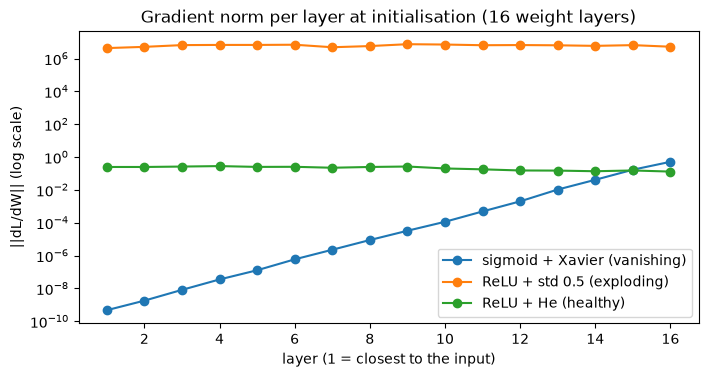

sigmoid + Xavier (vanishing)   layer1 4.67e-10   last 5.11e-01   ratio first/last 9.1e-10
ReLU + std 0.5 (exploding)     layer1 4.31e+06   last 5.22e+06   ratio first/last 8.2e-01
ReLU + He (healthy)            layer1 2.47e-01   last 1.29e-01   ratio first/last 1.9e+00


In [31]:
def grad_norms(init, act_cls, depth=15, width=64, seed=SEED):
    rng = np.random.default_rng(seed); layers, n_in = [], 64
    for _ in range(depth):
        layers += [Linear(n_in, width, init=init, rng=rng), act_cls()]; n_in = width
    layers.append(Linear(n_in, 10, init=init, rng=rng))
    net = Sequential(*layers); loss_fn = SoftmaxCrossEntropy()
    with np.errstate(over="ignore", invalid="ignore"):
        loss_fn.forward(net.forward(X_train[:128]), y_train[:128]); net.backward(loss_fn.backward())
    return [np.linalg.norm(l.grads["W"]) for l in net.param_layers()]

gn = {"sigmoid + Xavier (vanishing)": grad_norms("xavier", Sigmoid),
      "ReLU + std 0.5 (exploding)": grad_norms(0.5, ReLU),
      "ReLU + He (healthy)": grad_norms("he", ReLU)}
plt.figure(figsize=(8, 3.8))
for name, g in gn.items():
    plt.semilogy(range(1, len(g) + 1), g, "o-", label=name)
plt.xlabel("layer (1 = closest to the input)"); plt.ylabel("||dL/dW|| (log scale)")
plt.title("Gradient norm per layer at initialisation (16 weight layers)"); plt.legend(); plt.show()
for name, g in gn.items():
    print(f"{name:30s} layer1 {g[0]:.2e}   last {g[-1]:.2e}   ratio first/last {g[0]/g[-1]:.1e}")

**What just happened?** With sigmoid, the gradient reaching the first layer is many orders of magnitude smaller than at the last layer: early layers barely learn (**vanishing gradients**, each sigmoid multiplies by at most 0.25). With ReLU and too-large weights every layer's gradient is around $10^6$, millions of times too big (**exploding**): one SGD step would destroy the weights. ReLU + He keeps the norms within a small factor across all 16 layers. Residual connections, normalisation and careful initialisation are the three tools that make very deep networks trainable.

### 10.5 The checklist

| # | Check | How | Healthy sign |
|---|---|---|---|
| 1 | Initial loss | forward one batch before training | $\approx \ln K$ for $K$ balanced classes |
| 2 | Gradient check (new layers only) | central differences, float64, tiny input | relative error $< 10^{-7}$ |
| 3 | Overfit one batch | 1 batch, ~200 steps, no regularisation | loss → ~0, accuracy 100% |
| 4 | LR range test | Section 6.3 | pick ~1/10 of the LR at minimum loss |
| 5 | Loss curves | train and validation per epoch | both decrease; small gap |
| 6 | Activation statistics | std / histogram per layer | no layer collapsing to 0 or saturating |
| 7 | Dead units | fraction never active | small (a few %) |
| 8 | Gradient norms per layer | log plot | within ~1-2 orders of magnitude; no `nan` |
| 9 | Train/eval mode | dropout/BN behave differently | `eval()` for validation, `train()` after |
| 10 | Data | look at a few inputs and labels after preprocessing | images and labels match |

## 11. How this connects to modern AI

> 💬 **In plain English:** every large model today is trained with exactly these pieces, only bigger and on GPUs.

| What you built here | Where it lives in modern AI |
|---|---|
| `forward` / `backward` per layer, reversed loop | **Reverse-mode autodiff** in PyTorch (`autograd`), JAX and TensorFlow records the forward graph and runs exactly this loop |
| Gradient checking | `torch.autograd.gradcheck` is used to test every new custom CUDA kernel or layer |
| Xavier / He initialisation | default `nn.Linear`/`nn.Conv2d` initialisers; LLMs add depth-dependent scaling of residual branches (GPT-2 style) |
| Adam, weight decay, warm-up + cosine | **AdamW + linear warm-up + cosine decay** is the standard recipe for Transformers and LLMs |
| Dropout, early stopping | still used for fine-tuning and small-data tasks; very large pre-training runs often use little or no dropout |
| BatchNorm | CNNs (ResNet family); Transformers use **LayerNorm / RMSNorm** instead (Practice problem 7) |
| im2col + GEMM | one of the convolution algorithms in cuDNN and on CPUs; also why "everything is a matrix multiply" on GPUs and TPUs |
| Diagnostics checklist | what engineers do when an expensive training run diverges (loss spikes are often handled with clipping, lower LR and restarting from a checkpoint) |

Related notebooks: [`00_start_here_pytorch_from_zero.ipynb`](00_start_here_pytorch_from_zero.ipynb) (the same ideas with `autograd`), [`16_industry_pytorch_training_pipeline.ipynb`](16_industry_pytorch_training_pipeline.ipynb) (a production training loop), [`05_transformers_architecture.ipynb`](05_transformers_architecture.ipynb) (LayerNorm, residuals), [`14_Mathematics/06_optimization.ipynb`](../14_Mathematics/06_optimization.ipynb) (optimiser theory), [`06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb`](../06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb) (CNNs on real images).

## 12. Recap

- A layer is `forward` (compute and cache) plus `backward` (upstream gradient in, input gradient out, parameter gradients stored). **A gradient has the same shape as the thing it is a gradient of.**
- Linear: $\bar W = X^\top\bar Y$, $\bar b = \sum\bar Y$, $\bar X = \bar YW^\top$. Softmax + cross-entropy: $\bar z = (p - t)/N$, computed with the log-sum-exp trick.
- **Gradient checking** (central differences, relative error, float64) catches backward bugs; it costs 2 forwards per parameter, so use it on tiny inputs only.
- **Initialisation:** zero init never breaks symmetry; too small vanishes, too large saturates or explodes; **Xavier** for tanh/sigmoid, **He** for ReLU.
- **Optimisers:** momentum damps zig-zags, Adam adapts the step per parameter (with bias correction); use the **LR finder** and a decaying schedule (warm-up + cosine for Transformers).
- **Regularisation:** L2 / weight decay (AdamW decouples it), **inverted dropout** (scale by $1/q$ at train time, identity at eval), **early stopping** (restore the best epoch).
- **BatchNorm** normalises with batch statistics in training and running statistics in eval; its backward removes the mean and the $\hat x$-component of the gradient.
- **Conv via im2col** turns convolution into one matrix product; col2im scatter-adds gradients back. Max-pool sends the gradient to the arg-max.
- Debug with the **checklist**: initial loss ≈ ln K, overfit one batch, LR test, curves, activation stats, dead units, gradient norms.

## Practice problems

**1. (Easy, conceptual)** A Linear layer maps 784 → 128 and the batch size is 32. What are the shapes of $X$, $W$, $b$, $Y$, $\bar W$, $\bar b$ and $\bar X$?

<details><summary>Show solution</summary>

$X: 32\times784$, $W: 784\times128$, $b: 128$, $Y: 32\times128$. Gradients have the shape of what they differentiate: $\bar W: 784\times128$ ($=X^\top\bar Y$), $\bar b: 128$ (sum of $\bar Y$ over the batch), $\bar X: 32\times784$ ($=\bar YW^\top$).
</details>

**2. (Easy, conceptual)** Why does initialising all weights to the same constant fail, and why is it fine for biases?

<details><summary>Show solution</summary>

All hidden units in a layer then compute the same function, receive the same gradient and get the same update, so they stay identical forever (Section 5.1 showed 16 units remaining exact copies). The layer behaves like a single unit. Random weights break this symmetry; once they do, biases can start at 0 without causing it.
</details>

**3. (Easy, calculation)** A conv layer has input 3×32×32, 16 filters of size 5×5, padding 2, stride 2. Give the output shape, the number of parameters, and the shape of the im2col matrix for a batch of 4.

<details><summary>Show solution</summary>

$H_{out} = \lfloor(32+4-5)/2\rfloor+1 = 15+1 = 16$, so the output is $16\times16\times16$. Parameters: $16\cdot3\cdot25 + 16 = 1{,}216$. im2col: one row per output pixel per image, one column per (channel, kernel row, kernel column): $(4\cdot16\cdot16)\times(3\cdot25) = 1024\times75$.
</details>

**4. (Medium, coding)** Write a `LeakyReLU` layer ($y = x$ if $x>0$ else $\alpha x$) with `forward`/`backward` and gradient-check it.

<details><summary>Show solution</summary>

```python
import numpy as np

class LeakyReLU:
    def __init__(self, alpha=0.01):
        self.alpha = alpha
    def forward(self, x):
        self.x = x
        return np.where(x > 0, x, self.alpha * x)
    def backward(self, dout):
        return dout * np.where(self.x > 0, 1.0, self.alpha)

# gradient check with L = sum(forward(x) * G)
rng = np.random.default_rng(0)
x, G, h = rng.normal(size=(4, 5)), rng.normal(size=(4, 5)), 1e-5
layer = LeakyReLU(0.1); layer.forward(x); dx = layer.backward(G)
num = np.zeros_like(x)
for i in np.ndindex(x.shape):
    old = x[i]
    x[i] = old + h; fp = np.sum(layer.forward(x) * G)
    x[i] = old - h; fm = np.sum(layer.forward(x) * G)
    x[i] = old; num[i] = (fp - fm) / (2 * h)
err = np.max(np.abs(dx - num) / np.maximum(np.abs(dx) + np.abs(num), 1e-12))
print("relative error:", err)
assert err < 1e-7
```
</details>

**5. (Medium, coding)** Implement one RMSprop step ($s \leftarrow \rho s + (1-\rho)g^2$, $\theta \leftarrow \theta - \eta g/(\sqrt s+\epsilon)$) and use it to minimise $\tfrac12(a^2+25b^2)$ from $(-4, 1.5)$.

<details><summary>Show solution</summary>

```python
import numpy as np

def rmsprop_step(p, g, s, lr=0.01, rho=0.9, eps=1e-8):
    s[:] = rho * s + (1 - rho) * g * g          # running mean of squared gradients
    p[:] = p - lr * g / (np.sqrt(s) + eps)      # per-parameter step size
    return p, s

# minimise f(a, b) = 0.5 * (a^2 + 25 b^2)
p, s = np.array([-4.0, 1.5]), np.zeros(2)
for _ in range(500):
    g = np.array([p[0], 25 * p[1]])
    rmsprop_step(p, g, s, lr=0.01)
print("final point:", p.round(4))
assert np.all(np.abs(p) < 0.05)
```
RMSprop is Adam without the momentum term and without bias correction. Because the step is $g/\sqrt{s}$, both coordinates move at a similar speed despite the 25× difference in curvature.
</details>

**6. (Medium, conceptual)** With inverted dropout (keep probability $q=0.8$), what does a unit with input value 5 output in training mode when it is kept, when it is dropped, and in eval mode? What would go wrong in eval mode with *non-inverted* dropout if you forgot to rescale?

<details><summary>Show solution</summary>

Kept: $5/0.8 = 6.25$. Dropped: 0. Eval: 5 (identity). The expected training output is $0.8\cdot6.25 = 5$, matching eval. With non-inverted dropout (no $1/q$ during training) the network is trained on activations whose expected value is $0.8\cdot5 = 4$; if at test time you then skip the required ×$q$ rescaling, every activation is 25% larger than anything seen during training and predictions shift.
</details>

**7. (Hard, coding)** Implement **LayerNorm** (normalise each example across its features, learnable $\gamma,\beta$) with forward and backward, and gradient-check $\bar x$. Hint: it is BatchNorm with the sums taken over the other axis.

<details><summary>Show solution</summary>

```python
import numpy as np

class LayerNorm:
    # Normalise each ROW (example) over its D features; gamma, beta have shape (D,).
    def __init__(self, d, eps=1e-5):
        self.gamma, self.beta, self.eps = np.ones(d), np.zeros(d), eps
    def forward(self, x):
        mu = x.mean(axis=1, keepdims=True); var = x.var(axis=1, keepdims=True)
        self.inv = 1.0 / np.sqrt(var + self.eps); self.xhat = (x - mu) * self.inv
        return self.gamma * self.xhat + self.beta
    def backward(self, dout):
        d = dout.shape[1]
        self.dgamma = (dout * self.xhat).sum(axis=0); self.dbeta = dout.sum(axis=0)
        g = dout * self.gamma
        # same formula as BatchNorm, but the sums run over features (axis=1) instead of the batch
        return self.inv / d * (d * g - g.sum(axis=1, keepdims=True) - self.xhat * (g * self.xhat).sum(axis=1, keepdims=True))

rng = np.random.default_rng(1)
ln = LayerNorm(6); ln.gamma = rng.normal(size=6); ln.beta = rng.normal(size=6)
x, G, h = rng.normal(size=(3, 6)) * 2 + 1, rng.normal(size=(3, 6)), 1e-5
ln.forward(x); dx = ln.backward(G)
num = np.zeros_like(x)
for i in np.ndindex(x.shape):
    old = x[i]
    x[i] = old + h; fp = np.sum(ln.forward(x) * G)
    x[i] = old - h; fm = np.sum(ln.forward(x) * G)
    x[i] = old; num[i] = (fp - fm) / (2 * h)
err = np.max(np.abs(dx - num) / np.maximum(np.abs(dx) + np.abs(num), 1e-12))
print("LayerNorm dx relative error:", err)
assert err < 1e-7
```
</details>

**8. (Hard, conceptual)** Your 30-layer ReLU network's loss stays at exactly 2.3026 for 10 classes and never moves. List three plausible causes and the diagnostic for each.

<details><summary>Show solution</summary>

$2.3026 = \ln 10$ means the model outputs (near-)uniform probabilities. (a) **Dead network / vanishing signal**: too-small init or all ReLUs dead; check per-layer activation std and dead-unit fraction (Sections 5, 10.3). (b) **Vanishing gradients**: plot $\lVert\partial L/\partial W\rVert$ per layer (Section 10.4); fix with He init, normalisation, residual connections. (c) **Bug or data problem**: labels shuffled or not aligned, optimiser not stepping (e.g. learning rate 0, gradients not applied); try to overfit one batch (Section 10.1) and look at a few labelled examples.
</details>

## Further reading

- Goodfellow, Bengio & Courville, *Deep Learning* (MIT Press, 2016), Ch. 6 (feed-forward networks and back-propagation), 7 (regularisation), 8 (optimisation, including initialisation and batch normalisation), 9 (convolutional networks). Free at deeplearningbook.org.
- Glorot & Bengio (2010), "Understanding the difficulty of training deep feedforward neural networks"; He et al. (2015), "Delving Deep into Rectifiers"; Ioffe & Szegedy (2015), "Batch Normalization"; Srivastava et al. (2014), "Dropout"; Kingma & Ba (2015), "Adam"; Loshchilov & Hutter (2019), "Decoupled Weight Decay Regularization".
- Stanford **CS231n** course notes (free online): "Backpropagation, Intuitions", "Neural Networks Part 2: Setting up the Data and the Loss" and "Convolutional Networks", which use the same im2col view.
- Andrej Karpathy, "A Recipe for Training Neural Networks" (blog post, 2019): the origin of several items in our checklist.

## Next notebook

Continue with [`19_sequence_models_hands_on.ipynb`](19_sequence_models_hands_on.ipynb): RNN, LSTM and GRU cells from scratch, back-propagation through time, seq2seq and attention.